# MODIS to VIIRS harmonization, all of Algeria: the data decisions, tested

What this notebook does, in order. Every section prints a table and draws a figure, so each decision can be judged with numbers.

| Section | Question |
|---|---|
| 1 | Load the two archives for the whole country, with every detection type kept |
| A | Which detection types exist, and does their share change over the years? (why keep type 0 only) |
| B | When did each satellite start? (why drop 2000-2002) |
| C | Which months look like outages, by a rule that does not use our hand-made list? |
| D | How much did detections change from 2018-2021 to 2022-2025 for MODIS and VIIRS, and is the cause visible? |
| E | At what time of day did each satellite pass over Algeria, year by year? |
| F | Does the VIIRS / MODIS ratio drift, and does the type choice change it? |
| G | Build the block-month table (0.5 degree blocks) used by the models |
| H | The four translation models, each in its own block: straight curve, curved fit, gradient boosting, neural network |
| I | Compare the data decisions: type 0 vs all types, outages removed vs kept, training with or without the drift years |
| J | How stable is the neural network across random seeds? |
| K | Preview of the reconstruction 2000-2012 and the one-satellite problem |

How to run: set `RAWD` below (or the environment variable `FIRE_RAW`), then Run All. The raw archives must be the whole-country FIRMS files `modis_archive.csv` and `viirs_archive.csv`. Figures are saved to `FIGDIR` and the result tables to CSV there too.

Nothing in this notebook has been run on your real files. It was run end to end on made-up archives that contain a planted drop, planted outages and planted static sources, so the code works, but its numbers on your data are unknown until you run it.

In [3]:
import os
import calendar
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

# ------------------------------ settings ------------------------------
RAWD = Path(os.environ.get("FIRE_RAW", "../data/raw/algeria"))     # folder with modis_archive.csv and viirs_archive.csv
FIGDIR = Path(os.environ.get("FIRE_FIG", "../figures"))            # figures and result tables are saved here
FIGDIR.mkdir(parents=True, exist_ok=True)
CHUNK = 500_000
BLOCK = 0.5                                   # block size in degrees (about 50 km)
NORTH_LAT = 34.0                              # north = latitude >= 34.0, south = below
REF_YEARS, TEST_YEARS = (2018, 2021), (2022, 2025)      # periods compared in section D
HIDDEN_YEARS = (2013, 2015)                   # years used as the hidden test in section I
YOUR_OUTAGE_MONTHS = ["2017-12", "2018-10", "2022-04", "2022-07", "2022-08", "2024-01", "2024-02", "2024-06",
                      "2024-07", "2024-11", "2025-12", "2026-01", "2026-03", "2026-04", "2026-07"]
MIN_MISSING_DAYS = {"viirs": 1, "modis": 10}  # outage rule 1: a month with at least this many days without ANY detection (MODIS sees few static sources, so it needs a looser limit)
STATIC_RATIO_LIMIT = 0.5                      # outage rule 2: static-source detections below 50% of their normal level
LAST_FULL_YEAR = 2025                         # the analysis stops at the end of this year
T0 = time.time()

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (11, 4.2)})
RESULTS = {}                                  # every table is stored here and saved to CSV at the end

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIGDIR / f"{name}.png", dpi=130)
    plt.show()

def keep(name, table):
    RESULTS[name] = table
    return table
print("raw folder:", RAWD.resolve())

raw folder: C:\Everything\space-apps-fire\data\raw\algeria


## 1. Load both archives, whole country, every detection type kept

We keep all rows here, and filter later, so that the same loaded data can be used for the type 0 version and the all types version.
Each row gets: the day, the month (`ym`), the 0.01 degree cell (about 1 km, `cy`, `cx`), the 0.5 degree block (`by`, `bx`), the type code, the satellite name, the UTC hour, and a flag for nominal confidence or better (MODIS at least 30, VIIRS n or h).

In [4]:
def load(kind):
    path = RAWD / f"{kind}_archive.csv"
    header = pd.read_csv(path, nrows=0).columns.tolist()
    want = ["latitude", "longitude", "acq_date", "acq_time", "confidence", "type", "satellite"]
    use = [c for c in want if c in header]
    print(f"{kind}: columns used {use} | not in file {[c for c in want if c not in header]}")
    parts = []
    for ch in pd.read_csv(path, usecols=use, chunksize=CHUNK):
        out = pd.DataFrame({"lat": ch["latitude"].astype("float32"), "lon": ch["longitude"].astype("float32")})
        out["date"] = pd.to_datetime(ch["acq_date"])
        out["year"] = out.date.dt.year.astype("int16")
        out["month"] = out.date.dt.month.astype("int8")
        out["ym"] = out.date.dt.strftime("%Y-%m")
        out["cy"] = np.floor(ch["latitude"] / 0.01).astype("int32")
        out["cx"] = np.floor(ch["longitude"] / 0.01).astype("int32")
        out["by"] = np.floor(ch["latitude"] / BLOCK).astype("int32")
        out["bx"] = np.floor(ch["longitude"] / BLOCK).astype("int32")
        out["type"] = pd.to_numeric(ch["type"], errors="coerce").astype("float32") if "type" in ch else np.float32(np.nan)
        out["sat"] = ch["satellite"].astype(str) if "satellite" in ch else "unknown"
        t = pd.to_numeric(ch["acq_time"], errors="coerce") if "acq_time" in ch else pd.Series(np.nan, index=ch.index)
        out["hour"] = ((t // 100) + (t % 100) / 60).astype("float32")           # UTC decimal hour
        if kind == "viirs":
            out["conf_ok"] = ch["confidence"].astype(str).isin(["n", "h"])
        else:
            out["conf_ok"] = pd.to_numeric(ch["confidence"], errors="coerce") >= 30
        parts.append(out)
    df = pd.concat(parts, ignore_index=True)
    df = df[df.year <= LAST_FULL_YEAR]
    print(f"{kind}: {len(df):,} rows | {df.date.min().date()} to {df.date.max().date()}")
    return df

D = {"modis": load("modis"), "viirs": load("viirs")}
print("loaded in", round((time.time() - T0) / 60, 1), "min")

modis: columns used ['latitude', 'longitude', 'acq_date', 'acq_time', 'confidence', 'type', 'satellite'] | not in file []
modis: 225,466 rows | 2000-11-01 to 2025-12-31
viirs: columns used ['latitude', 'longitude', 'acq_date', 'acq_time', 'confidence', 'type', 'satellite'] | not in file []
viirs: 1,325,643 rows | 2012-07-04 to 2025-12-31
loaded in 0.3 min


## A. Detection types: what is in the files, and does it change over time?

FIRMS labels each detection: 0 = presumed vegetation fire, other codes = static land sources such as gas flares, volcanoes, or offshore detections (confirm the exact codes in the FIRMS readme that comes with your download).

Why this matters for the model: a static source fires every day, so it adds a constant offset that has nothing to do with burning activity, and the two sensors do not see these sources equally well.
Two things to look for in the figure: a large non-zero share (what we would be mixing in) and a sudden change of share in some year (a change in how the type was assigned, which would be a bias of its own).

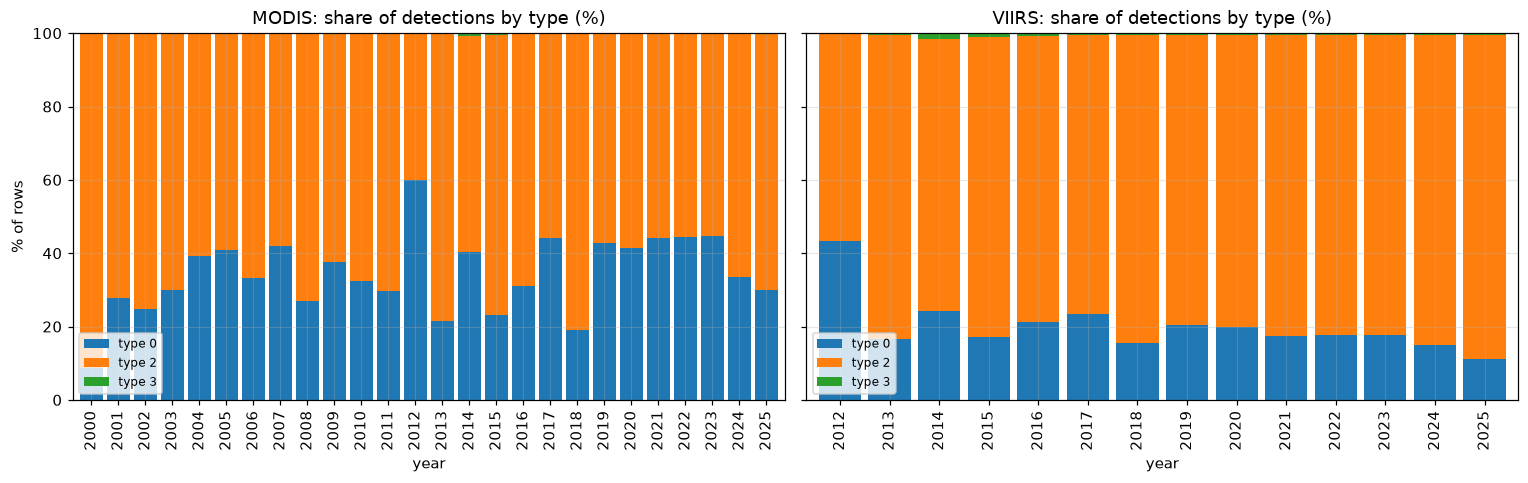

MODIS 2013-2025: 102,481 rows | not type 0 and labelled: 65,990 (64.4%) | unlabelled: 0
VIIRS 2013-2025: 1,175,118 rows | not type 0 and labelled: 959,030 (81.6%) | unlabelled: 0


,type 0,type 2,type 3
year,,,
2012,43.3,56.6,0.1
2013,16.5,83.1,0.4
2014,24.2,74.3,1.5
2015,17.1,81.8,1.1
2016,21.2,77.9,0.9
2017,23.3,76.2,0.4
2018,15.4,84.0,0.5
2019,20.4,79.2,0.4
2020,19.8,79.7,0.5


In [5]:
def type_share(df):
    d = df[df.conf_ok]
    label = d.type.fillna(-1).astype(int)
    counts = pd.crosstab(d.year, label)
    share = 100 * counts.div(counts.sum(axis=1), axis=0)
    share.columns = ["unlabelled" if c == -1 else f"type {int(c)}" for c in share.columns]
    return counts, share

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, kind in zip(axes, ["modis", "viirs"]):
    counts, share = type_share(D[kind])
    keep(f"A_type_share_{kind}", share.round(1))
    share.plot(kind="bar", stacked=True, ax=ax, width=0.85)
    ax.set_title(f"{kind.upper()}: share of detections by type (%)")
    ax.set_xlabel("year"); ax.set_ylabel("% of rows")
    ax.legend(loc="lower left", fontsize=8)
savefig("A_type_share")

for kind in ("modis", "viirs"):
    d = D[kind][D[kind].conf_ok & (D[kind].year >= 2013)]
    n_non0 = int(((d.type != 0) & d.type.notna()).sum())
    print(f"{kind.upper()} 2013-{LAST_FULL_YEAR}: {len(d):,} rows | not type 0 and labelled: {n_non0:,} ({100 * n_non0 / len(d):.1f}%) | unlabelled: {int(d.type.isna().sum()):,}")
display(keep("A_type_share_viirs_table", type_share(D["viirs"])[1].round(1)))

## B. Satellites: when did each one start?

The claim to test: before Aqua flew, MODIS had only one satellite (Terra), so it saw about half as many overpasses, and its counts are not comparable to later years.
The first dates below come from the archive itself, not from memory.


MODIS: first and last date per satellite


,first date,last date
sat,,
Aqua,2002-07-04,2025-12-31
Terra,2000-11-01,2025-12-31



VIIRS: first and last date per satellite


,first date,last date
sat,,
SNPP,2012-07-04,2025-12-31


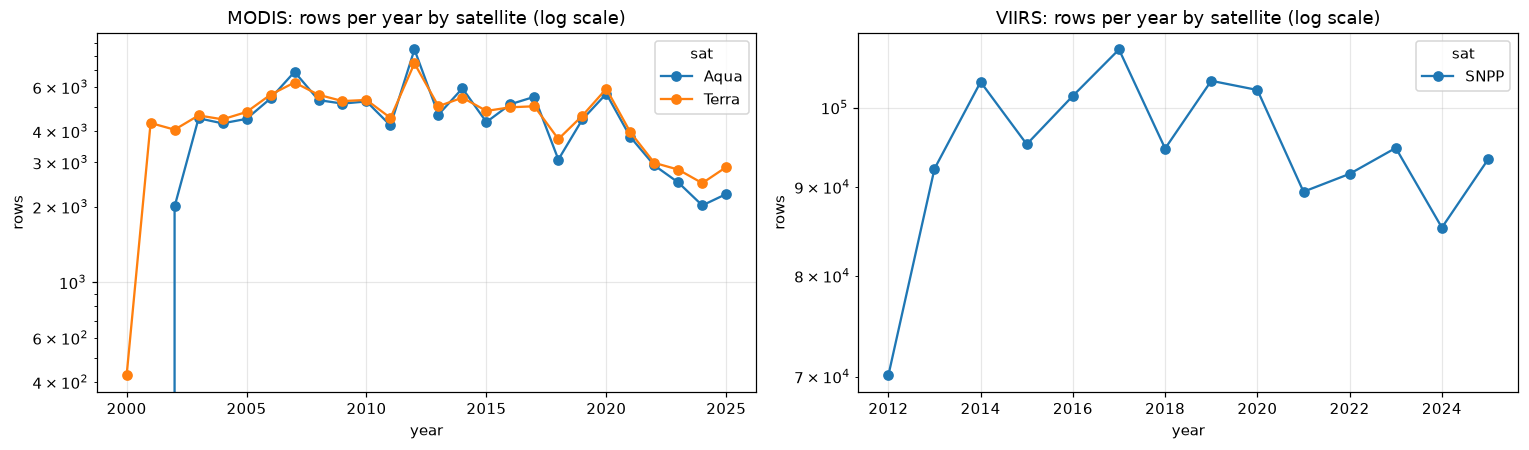

sat,Aqua,Terra,Terra+Aqua
year,,,
2000,0,34,34
2001,0,1082,1082
2002,511,895,1406
2003,1423,1098,2521
2004,1726,1415,3141
2005,1920,1554,3474
2006,1925,1391,3316
2007,3056,1951,5007
2008,1628,1106,2734


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, kind in zip(axes, ["modis", "viirs"]):
    d = D[kind]
    table = pd.crosstab(d.year, d.sat)
    table.plot(ax=ax, marker="o")
    ax.set_yscale("log")
    ax.set_title(f"{kind.upper()}: rows per year by satellite (log scale)")
    ax.set_xlabel("year"); ax.set_ylabel("rows")
    first_last = d.groupby("sat").date.agg(["min", "max"])
    first_last["min"], first_last["max"] = first_last["min"].dt.strftime("%Y-%m-%d"), first_last["max"].dt.strftime("%Y-%m-%d")
    print(f"\n{kind.upper()}: first and last date per satellite")
    display(first_last.rename(columns={"min": "first date", "max": "last date"}))
savefig("B_satellites")

modis_all = D["modis"][D["modis"].conf_ok & (D["modis"].type == 0)]
per_year = modis_all.drop_duplicates(["cy", "cx", "date", "sat"]).groupby(["year", "sat"]).size().unstack(fill_value=0)
per_year["Terra+Aqua"] = per_year.sum(axis=1)
display(keep("B_modis_cellday_per_year_by_satellite", per_year))

## C. Outage months: found by a rule, then compared with your list

Idea: a satellite that works detects something somewhere in Algeria almost every day, because static sources such as gas flares burn constantly. So an outage looks like (rule 1) calendar days with no detection at all, or (rule 2) a month where the static-source detections fall far below their normal level, while fire detections alone could be low simply because it was a quiet month.
Rule 2 only runs for months where almost all rows carry a type label (the most recent rows may have none).
The thresholds are my first choice and are not tuned. Read the table before trusting them.


VIIRS: 13 months flagged out of 155 checked


,days in month,days with a detection,days missing,labelled share,static detections,static / normal,flagged by,on your list
2021-08,31,30,1,1.0,6868,1.14,missing days,False
2022-07,31,26,5,1.0,6001,1.00,missing days,True
2022-08,31,21,10,1.0,5280,0.88,missing days,True
2023-07,31,30,1,1.0,6551,1.00,missing days,False
2023-11,30,29,1,1.0,6645,1.01,missing days,False
2024-01,31,30,1,1.0,5158,0.80,missing days,True
2024-05,31,29,2,1.0,5832,1.00,missing days,False
2024-06,30,27,3,1.0,5569,0.95,missing days,True
2024-07,31,19,12,1.0,4342,0.72,missing days,True
2024-09,30,28,2,1.0,5172,0.84,missing days,False


  your list inside the checked period: 10
  on your list and flagged by the rule: ['2022-07', '2022-08', '2024-01', '2024-06', '2024-07', '2024-11']
  on your list but NOT flagged:         ['2017-12', '2018-10', '2022-04', '2024-02']
  flagged but NOT on your list:         ['2021-08', '2023-07', '2023-11', '2024-05', '2024-09', '2025-07', '2025-11']

MODIS: 24 months flagged out of 275 checked


,days in month,days with a detection,days missing,labelled share,static detections,static / normal,flagged by,on your list
2006-02,28,28,0,1.0,282,0.42,static drop,False
2007-01,31,31,0,1.0,320,0.44,static drop,False
2007-02,28,26,2,1.0,310,0.43,static drop,False
2008-02,29,29,0,1.0,354,0.48,static drop,False
2009-01,31,29,2,1.0,260,0.44,static drop,False
2009-12,31,31,0,1.0,290,0.47,static drop,False
2010-02,28,28,0,1.0,297,0.48,static drop,False
2012-02,29,29,0,1.0,252,0.46,static drop,False
2014-01,31,30,1,1.0,287,0.42,static drop,False
2014-02,28,27,1,1.0,250,0.37,static drop,False


  your list inside the checked period: 10
  on your list and flagged by the rule: ['2017-12', '2024-01', '2024-02']
  on your list but NOT flagged:         ['2018-10', '2022-04', '2022-07', '2022-08', '2024-06', '2024-07', '2024-11']
  flagged but NOT on your list:         ['2006-02', '2007-01', '2007-02', '2008-02', '2009-01', '2009-12', '2010-02', '2012-02', '2014-01', '2014-02', '2015-01', '2015-02', '2016-02', '2016-12', '2017-02', '2018-01', '2018-02', '2021-11', '2022-01', '2022-02', '2025-11']


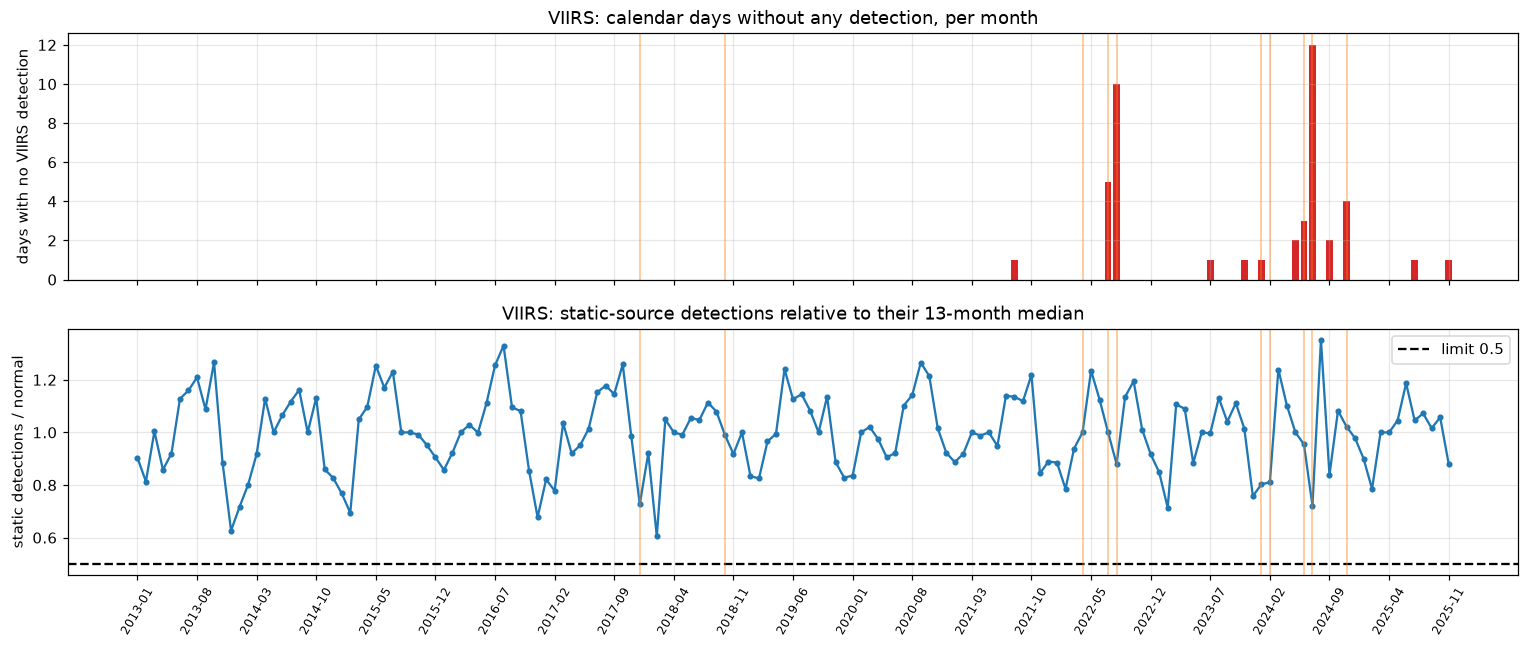

orange lines = months on your list


In [7]:
def month_table(kind, start):
    d = D[kind]
    last_ym = d.ym.max()                                                  # the last month may be partial and is left out
    months = [str(p) for p in pd.period_range(start, pd.Period(last_ym, "M") - 1, freq="M")]
    g = d[d.ym.isin(months)].groupby("ym")
    t = pd.DataFrame(index=months)
    t["days in month"] = [calendar.monthrange(int(m[:4]), int(m[5:7]))[1] for m in months]
    t["days with a detection"] = g.date.nunique().reindex(months).fillna(0).astype(int)
    t["days missing"] = t["days in month"] - t["days with a detection"]
    t["labelled share"] = g.type.apply(lambda s: s.notna().mean()).reindex(months)
    static = d[d.ym.isin(months) & d.type.notna() & (d.type != 0)].groupby("ym").size().reindex(months).fillna(0)
    t["static detections"] = static
    normal = static.rolling(13, center=True, min_periods=7).median().replace(0, np.nan)
    t["static / normal"] = static / normal
    rule1 = t["days missing"] >= MIN_MISSING_DAYS[kind]
    rule2 = (t["static / normal"] < STATIC_RATIO_LIMIT) & (t["labelled share"] >= 0.9)
    t["flagged by"] = np.where(rule1 & rule2, "both", np.where(rule1, "missing days", np.where(rule2, "static drop", "")))
    t["on your list"] = t.index.isin(YOUR_OUTAGE_MONTHS)
    return t

OUT = {}
for kind, start in (("viirs", "2013-01"), ("modis", "2003-01")):
    OUT[kind] = month_table(kind, start)
    flagged = OUT[kind][OUT[kind]["flagged by"] != ""]
    print(f"\n{kind.upper()}: {len(flagged)} months flagged out of {len(OUT[kind])} checked")
    display(keep(f"C_flagged_{kind}", flagged.round(2)))
    inside = [m for m in YOUR_OUTAGE_MONTHS if m in OUT[kind].index]
    print("  your list inside the checked period:", len(inside))
    print("  on your list and flagged by the rule:", [m for m in inside if OUT[kind].loc[m, "flagged by"] != ""])
    print("  on your list but NOT flagged:        ", [m for m in inside if OUT[kind].loc[m, "flagged by"] == ""])
    print("  flagged but NOT on your list:        ", [m for m in flagged.index if m not in YOUR_OUTAGE_MONTHS])

DETECTED = set(OUT["viirs"].index[OUT["viirs"]["flagged by"] != ""])
OUTAGE_USER = set(YOUR_OUTAGE_MONTHS)
OUTAGE_ALL = OUTAGE_USER | DETECTED                    # months removed from scoring and, in some scenarios, from training

t = OUT["viirs"]
x = np.arange(len(t))
fig, axes = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
axes[0].bar(x, t["days missing"], color="tab:red")
axes[0].set_ylabel("days with no VIIRS detection"); axes[0].set_title("VIIRS: calendar days without any detection, per month")
axes[1].plot(x, t["static / normal"], marker=".")
axes[1].axhline(STATIC_RATIO_LIMIT, color="k", ls="--", label=f"limit {STATIC_RATIO_LIMIT}")
axes[1].set_ylabel("static detections / normal"); axes[1].set_title("VIIRS: static-source detections relative to their 13-month median")
for ax in axes:
    for i, m in enumerate(t.index):
        if m in OUTAGE_USER:
            ax.axvline(i, color="tab:orange", alpha=0.5, lw=1)
step = max(1, len(t) // 20)
axes[1].set_xticks(x[::step]); axes[1].set_xticklabels(t.index[::step], rotation=60, fontsize=8)
axes[1].legend()
savefig("C_outages")
print("orange lines = months on your list")

## D. The 2022-2025 drop: MODIS against VIIRS

The claim to test: from 2018-2021 to 2022-2025 detections fell by about 49% for MODIS and about 9% for VIIRS.
We use fire cell-days (one 1 km cell counted once per day), compare the same calendar months in both periods so that the season mix cannot fake a change, and show the result with and without the outage months removed. The same is repeated for all detection types, for Terra and Aqua separately, and for the north and south of the country.

Why this matters for the model: if MODIS counts fell for reasons that are not about fire (a change in the satellites' overpass time, for example), then a model trained on those years learns a relationship that does not describe 2003-2012.

monthly series built: 24 | minutes so far: 0.5


,types,group,zone,change % (no month removed),change % (outage months removed)
0,type 0 only,MODIS Terra+Aqua,all,-38.8,-34.7
1,type 0 only,MODIS Terra+Aqua,north,-64.0,-64.3
2,type 0 only,MODIS Terra+Aqua,south,14.0,15.0
3,type 0 only,MODIS Terra,all,-33.6,-27.0
4,type 0 only,MODIS Terra,north,-67.8,-65.7
5,type 0 only,MODIS Terra,south,19.2,20.1
6,type 0 only,MODIS Aqua,all,-44.1,-42.9
7,type 0 only,MODIS Aqua,north,-61.2,-63.9
8,type 0 only,MODIS Aqua,south,3.0,3.5
9,type 0 only,VIIRS,all,-16.6,-9.0


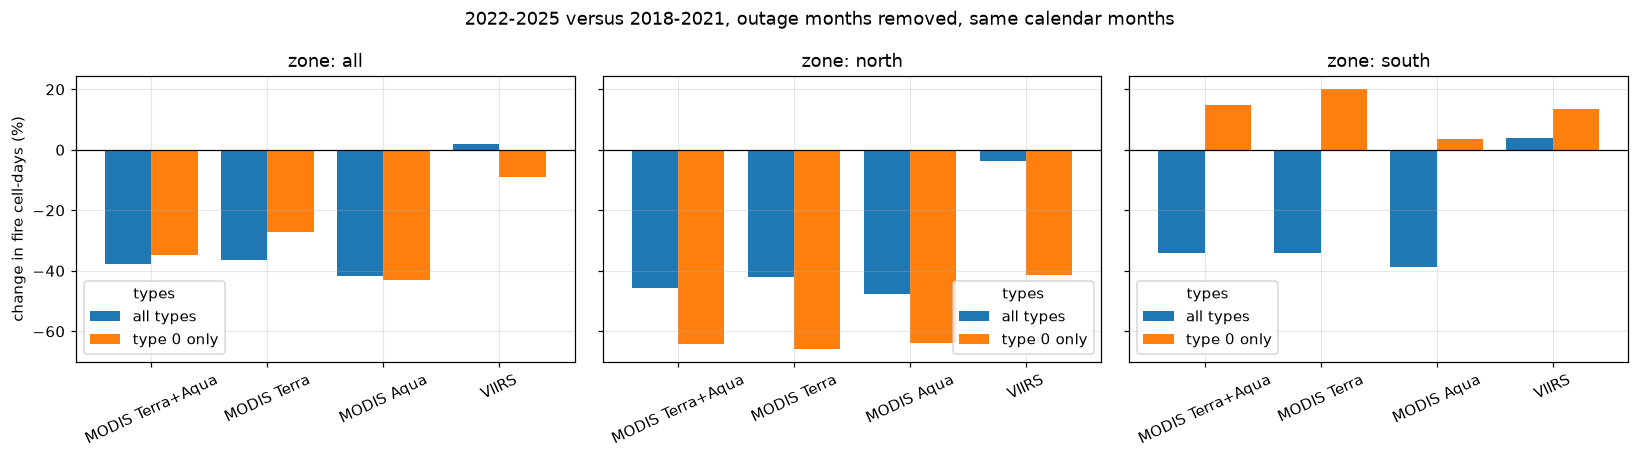

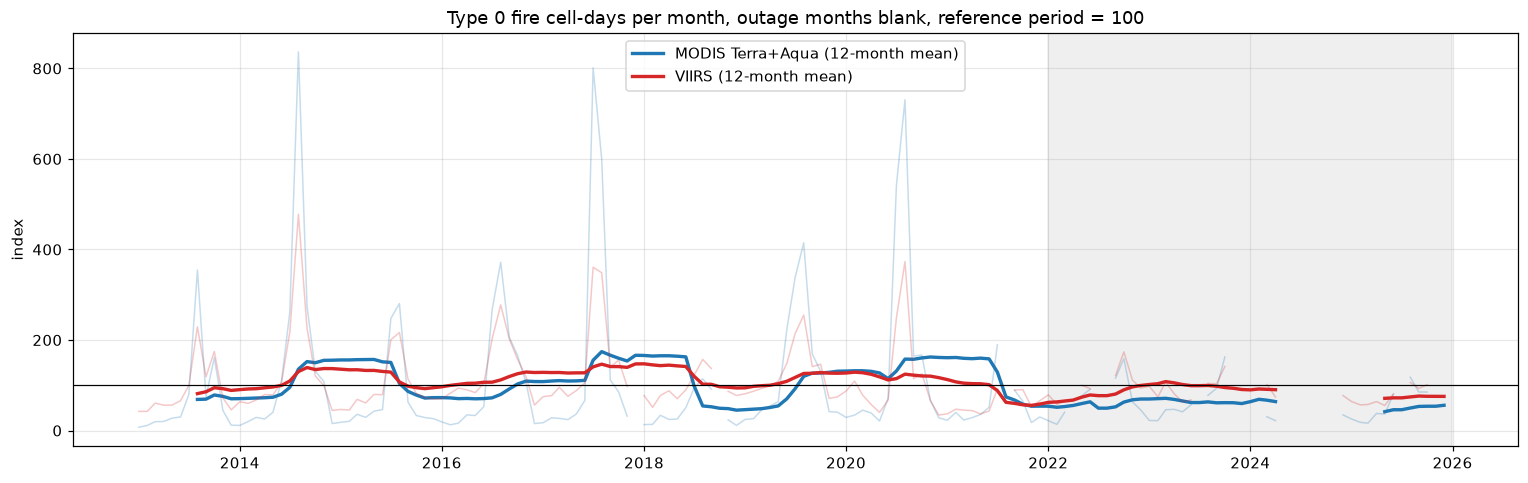

In [8]:
MONTHS_LONG = [str(p) for p in pd.period_range("2000-01", f"{LAST_FULL_YEAR}-12", freq="M")]
ZONES = {"all": lambda d: d, "north": lambda d: d[d.lat >= NORTH_LAT], "south": lambda d: d[d.lat < NORTH_LAT]}
GROUP_DEF = {"MODIS Terra+Aqua": ("modis", None), "MODIS Terra": ("modis", "Terra"),
             "MODIS Aqua": ("modis", "Aqua"), "VIIRS": ("viirs", None)}

def select(kind, scope):
    d = D[kind][D[kind].conf_ok]
    if scope == "type0":
        d = d[d.type == 0]
    return d

def monthly_series(d):
    d = d.drop_duplicates(["cy", "cx", "date"])                       # fire cell-days
    return d.groupby("ym").size().reindex(MONTHS_LONG).fillna(0)

SERIES = {}
for scope in ("type0", "all"):
    for group, (kind, sat) in GROUP_DEF.items():
        d = select(kind, scope)
        if sat:
            d = d[d.sat.str.contains(sat, case=False)]
        for zone, fn in ZONES.items():
            SERIES[(scope, group, zone)] = monthly_series(fn(d))
print("monthly series built:", len(SERIES), "| minutes so far:", round((time.time() - T0) / 60, 1))

def change(series, bad_months):
    s = series.drop(labels=[m for m in bad_months if m in series.index])
    df = pd.DataFrame({"n": s})
    df["year"], df["month"] = df.index.str[:4].astype(int), df.index.str[5:7].astype(int)
    ref = df[(df.year >= REF_YEARS[0]) & (df.year <= REF_YEARS[1])].groupby("month").n.mean()
    tst = df[(df.year >= TEST_YEARS[0]) & (df.year <= TEST_YEARS[1])].groupby("month").n.mean()
    common = ref.index.intersection(tst.index)                          # the same calendar months in both periods
    return 100 * (tst[common].sum() / ref[common].sum() - 1)

rows = []
for (scope, group, zone), s in SERIES.items():
    rows.append({"types": "type 0 only" if scope == "type0" else "all types", "group": group, "zone": zone,
                 "change % (no month removed)": change(s, set()),
                 "change % (outage months removed)": change(s, OUTAGE_ALL)})
CHANGE = pd.DataFrame(rows)
display(keep("D_change_2022_2025_vs_2018_2021", CHANGE.round(1)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
groups = list(GROUP_DEF)
for ax, zone in zip(axes, ZONES):
    sub = CHANGE[CHANGE.zone == zone].pivot(index="group", columns="types", values="change % (outage months removed)").reindex(groups)
    sub.plot(kind="bar", ax=ax, width=0.8)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"zone: {zone}"); ax.set_xlabel(""); ax.set_ylabel("change in fire cell-days (%)")
    ax.tick_params(axis="x", rotation=25)
fig.suptitle(f"{TEST_YEARS[0]}-{TEST_YEARS[1]} versus {REF_YEARS[0]}-{REF_YEARS[1]}, outage months removed, same calendar months")
savefig("D_change_by_group")

# the monthly series themselves, scaled so that the reference period averages 100
x = pd.to_datetime([m + "-01" for m in MONTHS_LONG])
fig, ax = plt.subplots(figsize=(14, 4.5))
for group, colour in (("MODIS Terra+Aqua", "tab:blue"), ("VIIRS", "tab:red")):
    s = SERIES[("type0", group, "all")].copy()
    s[s.index.isin(OUTAGE_ALL)] = np.nan
    ref_mean = s[[m for m in s.index if REF_YEARS[0] <= int(m[:4]) <= REF_YEARS[1]]].mean()
    s = 100 * s / ref_mean
    s.index = x
    s = s[s.index >= "2013-01-01"]
    ax.plot(s.index, s.values, color=colour, alpha=0.25, lw=1)
    ax.plot(s.index, s.rolling(12, min_periods=8).mean().values, color=colour, lw=2.2, label=f"{group} (12-month mean)")
ax.axvspan(pd.Timestamp(f"{TEST_YEARS[0]}-01-01"), pd.Timestamp(f"{TEST_YEARS[1]}-12-31"), color="grey", alpha=0.12)
ax.axhline(100, color="k", lw=0.8)
ax.set_title("Type 0 fire cell-days per month, outage months blank, reference period = 100"); ax.set_ylabel("index"); ax.legend()
savefig("D_monthly_index")

## E. Time of day: did the overpass change?

Satellites fly at fixed local times. If MODIS' passing time moved while VIIRS' did not, MODIS sees the daily fire cycle at a different moment, and its counts can change with no change in the fires.
Below: the median acquisition time (UTC, decimal hours, 13.5 = 13:30) of type 0 detections, per year. Algeria is within about one hour of UTC.

,MODIS Terra,MODIS Aqua,VIIRS
year,,,
2013,11.130000,12.87,11.43
2014,11.220000,12.87,11.92
2015,11.550000,12.95,2.28
2016,11.130000,12.75,2.27
2017,11.120000,12.75,2.40
2018,21.549999,2.13,1.92
2019,21.520000,12.45,2.22
2020,11.320000,12.75,11.77
2021,21.200001,12.35,2.32


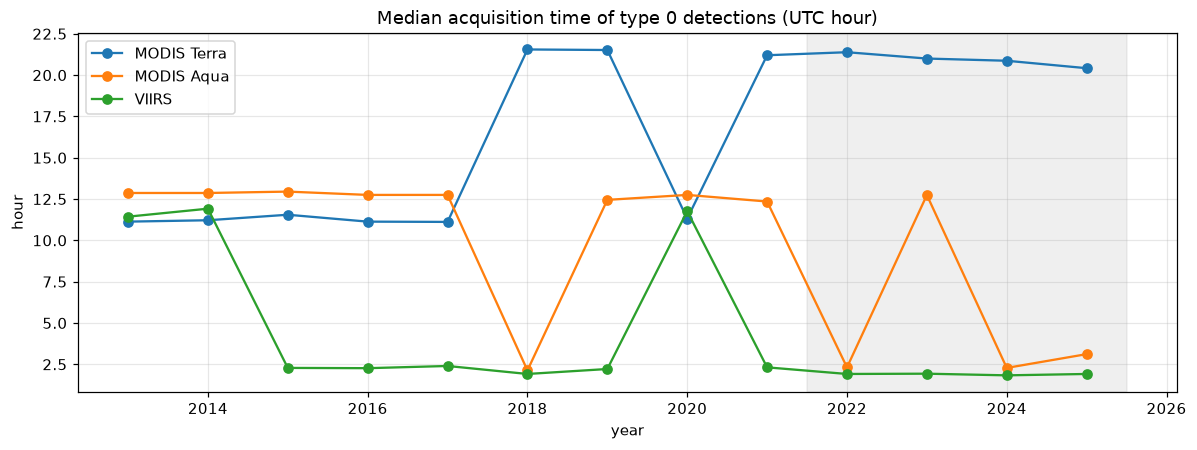

In [9]:
hour_groups = {"MODIS Terra": ("modis", "Terra"), "MODIS Aqua": ("modis", "Aqua"), "VIIRS": ("viirs", None)}
hours = {}
for group, (kind, sat) in hour_groups.items():
    d = select(kind, "type0")
    if sat:
        d = d[d.sat.str.contains(sat, case=False)]
    d = d[(d.year >= 2013) & (d.year <= LAST_FULL_YEAR)]
    hours[group] = d.groupby("year").hour.median()
HOURS = pd.DataFrame(hours)
display(keep("E_median_utc_hour_per_year", HOURS.round(2)))

fig, ax = plt.subplots(figsize=(11, 4.2))
for group in HOURS:
    ax.plot(HOURS.index, HOURS[group], marker="o", label=group)
ax.axvspan(TEST_YEARS[0] - 0.5, TEST_YEARS[1] + 0.5, color="grey", alpha=0.12)
ax.set_title("Median acquisition time of type 0 detections (UTC hour)"); ax.set_xlabel("year"); ax.set_ylabel("hour"); ax.legend()
savefig("E_overpass_hour")

## F. Does the VIIRS / MODIS relationship drift, and does the type choice change it?

For every year: total VIIRS fire cell-days divided by total MODIS (Terra+Aqua) fire cell-days, outage months removed.
A flat line means the two sensors keep the same proportion. A line that bends means one curve cannot translate all years, whatever model we use.

type0                 all              
       all north  south    all  north  south
ym                                          
2013  4.89  2.89  11.78   5.61   3.54   6.92
2014  3.41  2.38   9.91   5.23   3.17   7.42
2015  5.04  2.80  11.00   6.19   5.21   6.56
2016  4.58  2.48  11.77   5.95   4.48   6.65
2017  3.42  2.02  13.12   5.88   3.53   7.71
2018  8.07  4.91  10.27   8.44   9.27   8.27
2019  3.74  2.59   5.28   6.84   4.89   7.83
2020  2.80  2.16   5.33   5.22   3.54   6.48
2021  4.19  3.39   5.05   8.76   7.95   9.02
2022  5.53  4.78   5.86  11.39   9.36  12.10
2023  5.88  4.35   6.93  12.44   9.41  13.80
2024  6.88  4.08   8.14  13.22  11.70  13.69
2025  5.23  4.31   5.74  10.47   9.07  10.95

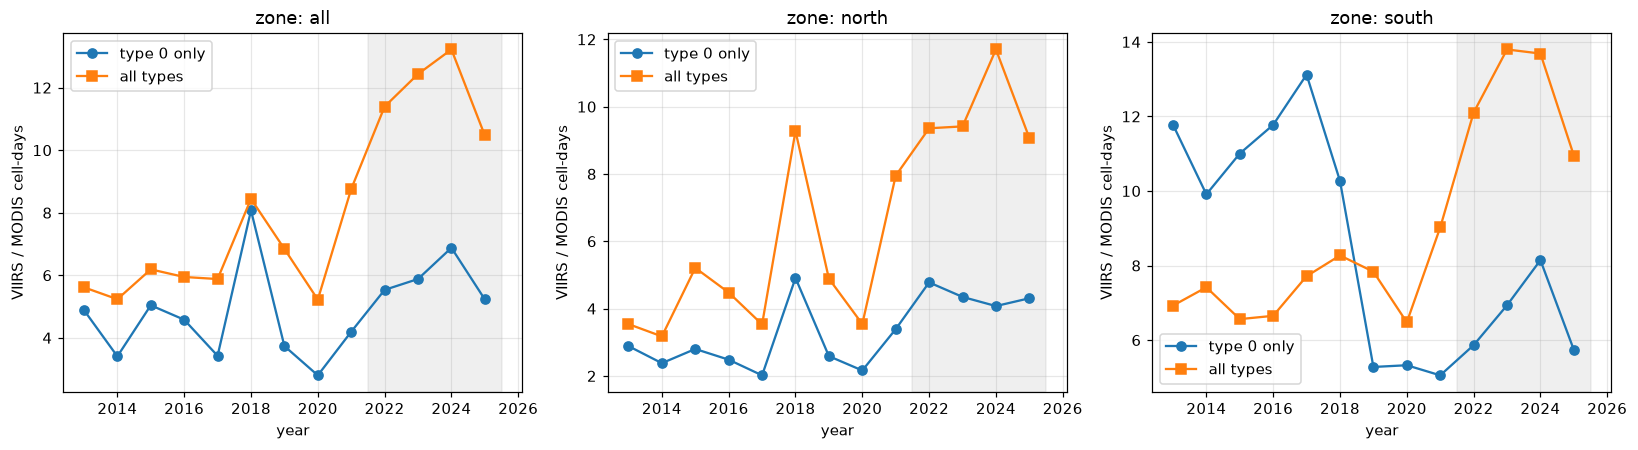

In [10]:
ratios = {}
for scope in ("type0", "all"):
    for zone in ZONES:
        v = SERIES[(scope, "VIIRS", zone)].drop(labels=[m for m in OUTAGE_ALL if m in MONTHS_LONG])
        m = SERIES[(scope, "MODIS Terra+Aqua", zone)].drop(labels=[m for m in OUTAGE_ALL if m in MONTHS_LONG])
        v, m = v[[k for k in v.index if int(k[:4]) >= 2013]], m[[k for k in m.index if int(k[:4]) >= 2013]]
        ratios[(scope, zone)] = v.groupby(lambda k: int(k[:4])).sum() / m.groupby(lambda k: int(k[:4])).sum()
RATIO = pd.DataFrame(ratios)
display(keep("F_viirs_over_modis_per_year", RATIO.round(2)))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
for ax, zone in zip(axes, ZONES):
    ax.plot(RATIO.index, RATIO[("type0", zone)], marker="o", label="type 0 only")
    ax.plot(RATIO.index, RATIO[("all", zone)], marker="s", label="all types")
    ax.axvspan(TEST_YEARS[0] - 0.5, TEST_YEARS[1] + 0.5, color="grey", alpha=0.12)
    ax.set_title(f"zone: {zone}"); ax.set_xlabel("year"); ax.set_ylabel("VIIRS / MODIS cell-days"); ax.legend()
savefig("F_ratio_per_year")

## G. The block-month table used by the models

Unit: one 0.5 degree block in one month. Targets and inputs are fire cell-days (not rows), so the 375 m pixel size of VIIRS does not enter the model; a separate factor can convert to rows at the very end.

- target `v`: VIIRS cell-days in the block-month (known from 2013-01; unknown before)
- inputs: `lm_all`, `lm_terra`, `lm_aqua` = log(1 + MODIS cell-days, all / Terra only / Aqua only), the block centre (`blat`, `blon`), and the month as a sine and cosine
- rows: every block that has any detection from 2013 on, for every month from 2000-11 to the end of the analysis, zeros included

There is deliberately no year input: the reconstruction of 2003-2012 must not depend on a year the model never saw.

In [11]:
MONTHS_BM = [str(p) for p in pd.period_range("2000-11", f"{LAST_FULL_YEAR}-12", freq="M")]

def block_month_table(scope):
    modis, viirs = select("modis", scope), select("viirs", scope)
    def counts(d):
        d = d.drop_duplicates(["cy", "cx", "date"])
        return d.groupby(["by", "bx", "ym"]).size()
    m_all = counts(modis)
    m_terra = counts(modis[modis.sat.str.contains("Terra", case=False)])
    m_aqua = counts(modis[modis.sat.str.contains("Aqua", case=False)])
    v = counts(viirs[viirs.date >= "2013-01-01"])
    in_range = m_all.index.get_level_values("ym") >= "2013-01"
    blocks = pd.concat([m_all[in_range].reset_index()[["by", "bx"]], v.reset_index()[["by", "bx"]]]).drop_duplicates().reset_index(drop=True)
    bm = blocks.merge(pd.DataFrame({"ym": MONTHS_BM}), how="cross")
    idx = pd.MultiIndex.from_frame(bm[["by", "bx", "ym"]])
    bm["m_all"] = m_all.reindex(idx).fillna(0).to_numpy()
    bm["m_terra"] = m_terra.reindex(idx).fillna(0).to_numpy()
    bm["m_aqua"] = m_aqua.reindex(idx).fillna(0).to_numpy()
    bm["v"] = v.reindex(idx).fillna(0).to_numpy()
    bm.loc[bm.ym < "2013-01", "v"] = np.nan                    # no VIIRS truth before 2013
    bm["year"], bm["month"] = bm.ym.str[:4].astype(int), bm.ym.str[5:7].astype(int)
    bm["blat"], bm["blon"] = (bm.by + 0.5) * BLOCK, (bm.bx + 0.5) * BLOCK
    bm["msin"], bm["mcos"] = np.sin(2 * np.pi * bm.month / 12), np.cos(2 * np.pi * bm.month / 12)
    for c in ("all", "terra", "aqua"):
        bm["lm_" + c] = np.log1p(bm["m_" + c])
    return bm

BM = {scope: block_month_table(scope) for scope in ("type0", "all")}
summary = {}
for scope, bm in BM.items():
    known = bm[bm.v.notna()]
    summary[scope] = {"blocks": bm[["by", "bx"]].drop_duplicates().shape[0], "rows": len(bm),
                      "VIIRS cell-days 2013+": known.v.sum(), "MODIS cell-days 2013+": bm[bm.year >= 2013].m_all.sum(),
                      "share of VIIRS cell-days in blocks with no MODIS that month (%)": 100 * known[known.m_all == 0].v.sum() / known.v.sum()}
display(keep("G_block_month_summary", pd.DataFrame(summary).round(1)))
print("minutes so far:", round((time.time() - T0) / 60, 1))

,type0,all
blocks,444.0,444.0
rows,134088.0,134088.0
VIIRS cell-days 2013+,138086.0,642466.0
MODIS cell-days 2013+,33810.0,91082.0
share of VIIRS cell-days in blocks with no MODIS that month (%),36.3,24.2


minutes so far: 0.6


## H. The four translation models

Each block below is one model. All of them take the training rows of one scenario and return a `predict` function.
All four are calibrated so that their total over the training rows equals the real VIIRS total (the factor `smear`), because the models for log-counts otherwise tend to under-predict totals.

1. **Straight log-log curve:** `log(1+VIIRS) = a + b * log(1+MODIS)`. One line for the whole country.
2. **Curved fit:** the same with a squared term, so the curve can bend at high activity (this was the best total model in the earlier work).
3. **Gradient boosting (machine learning):** many small decision trees, trained with a Poisson loss because the target is a count.
4. **Neural network (deep learning):** two hidden layers of 64 and 32 units, trained on `log(1+VIIRS)`, stopping itself when its internal validation score stops improving.

Only the cell-level and block-level inputs listed in section G are used. All inputs come from MODIS, so the same models can run in 2000-2012.

In [12]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

FEATURES = ["lm_all", "lm_terra", "lm_aqua", "blat", "blon", "msin", "mcos"]

# ---------------- model 1: straight log-log curve ----------------
def fit_straight(train):
    x = train["lm_all"].to_numpy()
    y = np.log1p(train["v"].to_numpy())
    b, a = np.polyfit(x, y, 1)                                           # y = a + b x
    smear = train["v"].sum() / np.expm1(a + b * x).sum()                 # makes the training total match
    def predict(df):
        return np.clip(np.expm1(a + b * df["lm_all"].to_numpy()), 0, None) * smear
    return predict

# ---------------- model 2: curved (quadratic) log-log fit ----------------
def fit_curved(train):
    x = train["lm_all"].to_numpy()
    y = np.log1p(train["v"].to_numpy())
    c2, c1, c0 = np.polyfit(x, y, 2)                                     # y = c0 + c1 x + c2 x^2
    smear = train["v"].sum() / np.expm1(c0 + c1 * x + c2 * x ** 2).sum()
    def predict(df):
        z = df["lm_all"].to_numpy()
        return np.clip(np.expm1(c0 + c1 * z + c2 * z ** 2), 0, None) * smear
    return predict

# ---------------- model 3: gradient boosting ----------------
def fit_gradient_boosting(train):
    model = HistGradientBoostingRegressor(loss="poisson", max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                          min_samples_leaf=50, l2_regularization=1.0, random_state=0)
    model.fit(train[FEATURES], train["v"])
    def predict(df):
        return model.predict(df[FEATURES])
    return predict

# ---------------- model 4: neural network ----------------
def fit_neural_network(train, seed=0):
    scaler = StandardScaler().fit(train[FEATURES])
    model = MLPRegressor(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200, random_state=seed)
    model.fit(scaler.transform(train[FEATURES]), np.log1p(train["v"]))
    fitted = np.clip(np.expm1(model.predict(scaler.transform(train[FEATURES]))), 0, None)
    smear = train["v"].sum() / fitted.sum()
    def predict(df):
        return np.clip(np.expm1(model.predict(scaler.transform(df[FEATURES]))), 0, None) * smear
    return predict

MODEL_FITS = {"straight log-log": fit_straight, "curved log-quadratic": fit_curved,
              "gradient boosting": fit_gradient_boosting, "neural network": fit_neural_network}

# ---------------- the score ----------------
def score(df, predicted, months):
    mask = df.ym.isin(months).to_numpy()                       # keep only the months being scored
    d = df[mask].copy()
    d["pred"] = np.asarray(predicted)[mask]
    monthly = d.groupby("ym")[["v", "pred"]].sum()
    monthly = monthly[monthly.v > 0]
    out = {"median monthly error (%)": 100 * np.median(np.abs(monthly.pred - monthly.v) / monthly.v),
           "total bias (%)": 100 * (monthly.pred.sum() / monthly.v.sum() - 1),
           "block MAE (cell-days)": float(np.mean(np.abs(d.pred - d.v))),
           "block RMSE (cell-days)": float(np.sqrt(np.mean((d.pred - d.v) ** 2))),
           "block Spearman": d["v"].corr(d["pred"], method="spearman")}
    for name, mask in (("north", d.blat >= NORTH_LAT), ("south", d.blat < NORTH_LAT)):
        out[f"bias {name} (%)"] = 100 * (d.pred[mask].sum() / d.v[mask].sum() - 1) if d.v[mask].sum() > 0 else np.nan
    return out
print("models defined")

models defined


## I. Comparing the data decisions

The same four models are trained in four scenarios and scored on the same hidden test: 2013-2015 (VIIRS hidden), excluding outage months. The scenarios change one decision at a time:

- **S1** type 0 only, outage months removed from training, trained on 2016-2021 (years with stable MODIS overpass times; the choice we want to defend)
- **S2** the same, but trained on 2016-2025 (adds the drift years to the training data)
- **S3** like S2, but with the outage months kept in training
- **S4** all detection types, outage months removed, trained on 2016-2021

Read S1 against S2 for the drift years, S2 against S3 for the outage months, S1 against S4 for the type choice.
One caution: S4 is scored against all-type VIIRS counts, a different target from the other three, so only its relative errors (the percentages) can be compared, not its block errors in cell-days.

In [13]:
def months_in(y0, y1):
    return [m for m in MONTHS_BM if y0 <= int(m[:4]) <= y1]

TEST_MONTHS = [m for m in months_in(*HIDDEN_YEARS) if m not in OUTAGE_ALL]
SCENARIOS = {
    "S1 type0 | outages removed | train 2016-2021": dict(scope="type0", drop_outages=True, train=(2016, 2021)),
    "S2 type0 | outages removed | train 2016-2025": dict(scope="type0", drop_outages=True, train=(2016, 2025)),
    "S3 type0 | outages KEPT | train 2016-2025": dict(scope="type0", drop_outages=False, train=(2016, 2025)),
    "S4 ALL types | outages removed | train 2016-2021": dict(scope="all", drop_outages=True, train=(2016, 2021)),
}
print("test months:", len(TEST_MONTHS), "| hidden years", HIDDEN_YEARS)

rows, TRAINED = [], {}
for sname, cfg in SCENARIOS.items():
    bm = BM[cfg["scope"]]
    train_months = months_in(*cfg["train"])
    if cfg["drop_outages"]:
        train_months = [m for m in train_months if m not in OUTAGE_ALL]
    train = bm[bm.ym.isin(train_months) & bm.v.notna()]
    test = bm[bm.ym.isin(TEST_MONTHS)]
    for mname, fit in MODEL_FITS.items():
        predict = fit(train)
        TRAINED[(sname, mname)] = predict
        res = score(test, predict(test), TEST_MONTHS)
        res.update({"scenario": sname, "model": mname, "train rows": len(train)})
        rows.append(res)
    print(sname, "done | minutes so far:", round((time.time() - T0) / 60, 1))
SCEN = pd.DataFrame(rows)
cols = ["scenario", "model", "train rows", "median monthly error (%)", "total bias (%)", "bias north (%)", "bias south (%)",
        "block MAE (cell-days)", "block RMSE (cell-days)", "block Spearman"]
display(keep("I_scenarios", SCEN[cols].round(2)))

test months: 36 | hidden years (2013, 2015)
S1 type0 | outages removed | train 2016-2021 done | minutes so far: 1.0
S2 type0 | outages removed | train 2016-2025 done | minutes so far: 1.4
S3 type0 | outages KEPT | train 2016-2025 done | minutes so far: 1.7
S4 ALL types | outages removed | train 2016-2021 done | minutes so far: 2.2


,scenario,model,train rows,median monthly error (%),total bias (%),bias north (%),bias south (%),block MAE (cell-days),block RMSE (cell-days),block Spearman
0,S1 type0 | outages removed | train 2016-2021,straight log-log,30636,36.91,-5.31,36.47,-47.75,2.07,12.18,0.57
1,S1 type0 | outages removed | train 2016-2021,curved log-quadratic,30636,18.96,-2.81,27.28,-33.38,1.99,9.15,0.57
2,S1 type0 | outages removed | train 2016-2021,gradient boosting,30636,13.88,2.86,-3.96,9.78,1.74,7.34,0.54
3,S1 type0 | outages removed | train 2016-2021,neural network,30636,25.09,-4.44,29.23,-38.65,1.82,9.23,0.51
4,S2 type0 | outages removed | train 2016-2025,straight log-log,45288,32.17,2.64,48.47,-43.91,2.20,13.33,0.57
5,S2 type0 | outages removed | train 2016-2025,curved log-quadratic,45288,15.21,0.08,29.42,-29.73,2.03,9.17,0.57
6,S2 type0 | outages removed | train 2016-2025,gradient boosting,45288,15.30,-0.49,-7.61,6.75,1.75,7.55,0.54
7,S2 type0 | outages removed | train 2016-2025,neural network,45288,18.72,5.33,45.08,-35.05,1.97,9.80,0.53
8,S3 type0 | outages KEPT | train 2016-2025,straight log-log,53280,33.92,-2.66,39.41,-45.41,2.11,12.32,0.57
9,S3 type0 | outages KEPT | train 2016-2025,curved log-quadratic,53280,16.90,-1.86,26.80,-30.97,2.01,9.11,0.57


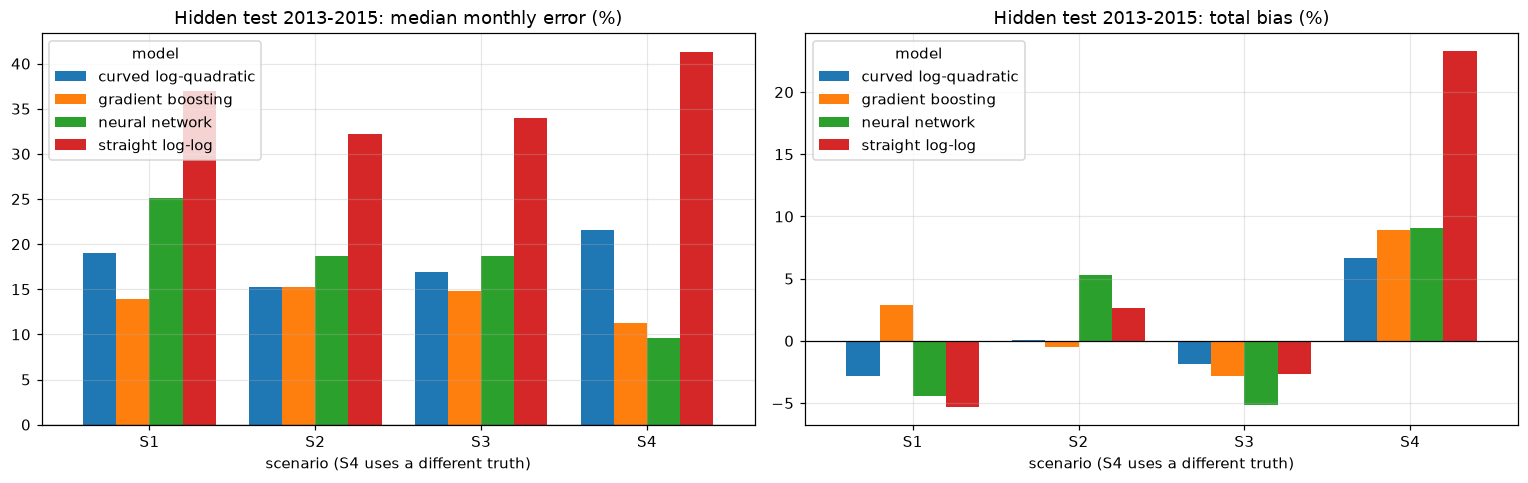

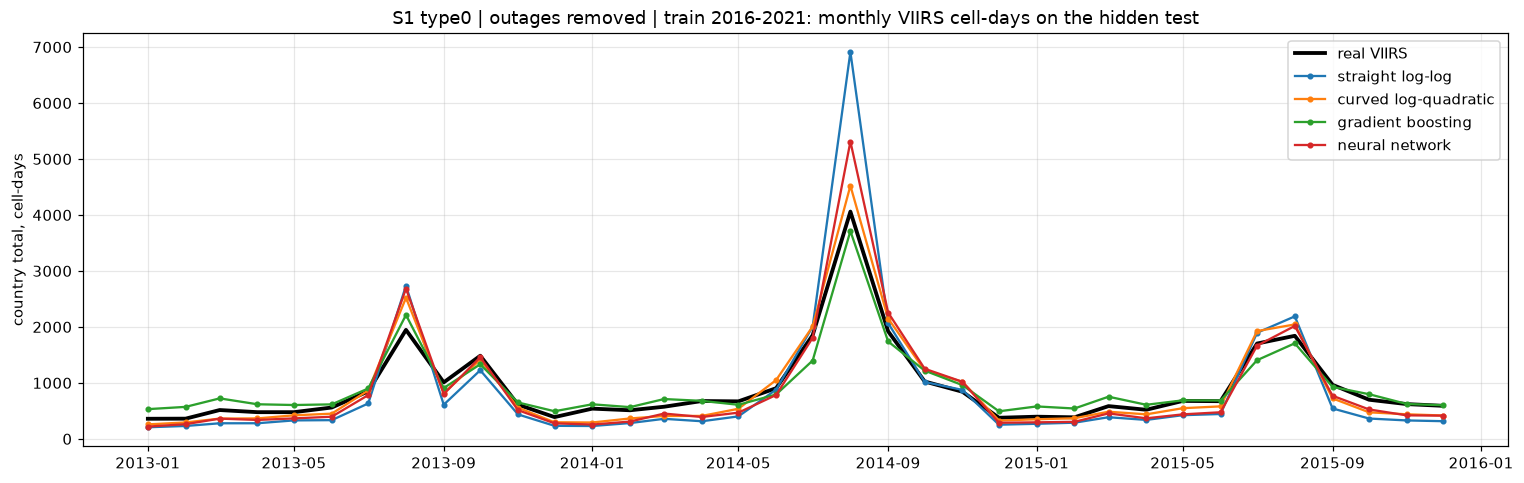

In [14]:
short = {s: s.split(" ")[0] for s in SCENARIOS}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["median monthly error (%)", "total bias (%)"]):
    pivot = SCEN.pivot(index="scenario", columns="model", values=metric).reindex(list(SCENARIOS))
    pivot.index = [short[s] for s in pivot.index]
    pivot.plot(kind="bar", ax=ax, width=0.8)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"Hidden test {HIDDEN_YEARS[0]}-{HIDDEN_YEARS[1]}: {metric}"); ax.set_xlabel("scenario (S4 uses a different truth)")
    ax.tick_params(axis="x", rotation=0)
savefig("I_scenario_comparison")

# predicted against actual monthly totals in the test months, scenario S1
s1 = list(SCENARIOS)[0]
bm = BM["type0"]
test = bm[bm.ym.isin(TEST_MONTHS)]
fig, ax = plt.subplots(figsize=(14, 4.5))
actual = test.groupby("ym").v.sum()
ax.plot(pd.to_datetime(actual.index + "-01"), actual.values, color="k", lw=2.5, label="real VIIRS")
for mname in MODEL_FITS:
    pred = TRAINED[(s1, mname)](test)
    monthly = pd.Series(pred, index=test.index).groupby(test.ym).sum()
    ax.plot(pd.to_datetime(monthly.index + "-01"), monthly.values, marker=".", label=mname)
ax.set_title(f"{s1}: monthly VIIRS cell-days on the hidden test"); ax.set_ylabel("country total, cell-days"); ax.legend()
savefig("I_test_monthly_totals")

,straight log-log,curved log-quadratic,gradient boosting,neural network
year,,,,
2013,-16.6,-4.6,12.4,-6.4
2014,11.8,2.6,-3.2,4.6
2015,-19.4,-8.9,2.7,-15.6
2016,-17.9,-8.7,-9.8,-13.3
2017,15.2,-7.9,-8.7,6.4
2018,-45.1,-29.2,-9.9,-33.8
2019,-0.9,5.2,-3.9,-2.9
2020,35.1,24.1,13.1,27.7
2021,2.8,23.0,47.7,16.4


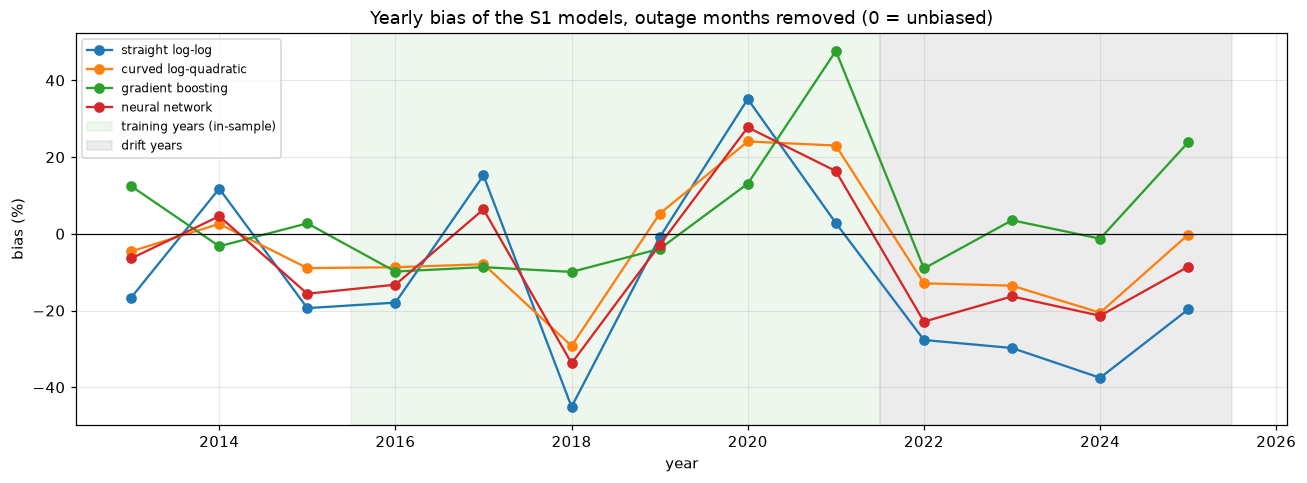

In [15]:
# the same models (scenario S1, trained 2016-2021) applied to every year with real VIIRS: where does the bias drift?
valid_months = [m for m in MONTHS_BM if int(m[:4]) >= 2013 and m not in OUTAGE_ALL]
all_years = BM["type0"][BM["type0"].ym.isin(valid_months)]
yearly = {}
for mname in MODEL_FITS:
    pred = pd.Series(TRAINED[(s1, mname)](all_years), index=all_years.index)
    by_year = pd.DataFrame({"v": all_years.v, "pred": pred, "year": all_years.year}).groupby("year")[["v", "pred"]].sum()
    yearly[mname] = 100 * (by_year.pred / by_year.v - 1)
YEARLY = pd.DataFrame(yearly)
display(keep("I_yearly_bias_S1", YEARLY.round(1)))

fig, ax = plt.subplots(figsize=(12, 4.5))
for mname in YEARLY:
    ax.plot(YEARLY.index, YEARLY[mname], marker="o", label=mname)
ax.axhline(0, color="k", lw=0.8)
ax.axvspan(2015.5, 2021.5, color="tab:green", alpha=0.08, label="training years (in-sample)")
ax.axvspan(TEST_YEARS[0] - 0.5, TEST_YEARS[1] + 0.5, color="grey", alpha=0.15, label="drift years")
ax.set_title("Yearly bias of the S1 models, outage months removed (0 = unbiased)"); ax.set_xlabel("year"); ax.set_ylabel("bias (%)"); ax.legend(fontsize=8)
savefig("I_yearly_bias")

## J. How stable is the neural network?

A neural network starts from random weights, so two runs give different answers. Before comparing it with anything, we need to know how large that wobble is.
Same data (scenario S1), five different random seeds.

In [16]:
bm = BM["type0"]
cfg = SCENARIOS[s1]
train_months = [m for m in months_in(*cfg["train"]) if m not in OUTAGE_ALL]
train = bm[bm.ym.isin(train_months) & bm.v.notna()]
test = bm[bm.ym.isin(TEST_MONTHS)]
seed_rows = []
for seed in range(5):
    predict = fit_neural_network(train, seed=seed)
    res = score(test, predict(test), TEST_MONTHS)
    seed_rows.append({"seed": seed, "median monthly error (%)": res["median monthly error (%)"],
                      "total bias (%)": res["total bias (%)"], "block MAE (cell-days)": res["block MAE (cell-days)"]})
SEEDS = pd.DataFrame(seed_rows).set_index("seed")
display(keep("J_nn_seeds", SEEDS.round(2)))
print("mean:", SEEDS.mean().round(2).to_dict())
print("std: ", SEEDS.std().round(2).to_dict())
gb_row = SCEN[(SCEN.scenario == s1) & (SCEN.model == "gradient boosting")].iloc[0]
print("gradient boosting, same scenario (one fit, deterministic):", round(gb_row["median monthly error (%)"], 2), "%  /  bias", round(gb_row["total bias (%)"], 2), "%")

,median monthly error (%),total bias (%),block MAE (cell-days)
seed,,,
0,25.09,-4.44,1.82
1,25.62,-0.68,1.91
2,20.90,-2.37,1.78
3,13.22,-3.89,1.77
4,17.22,-1.77,1.76


mean: {'median monthly error (%)': 20.41, 'total bias (%)': -2.63, 'block MAE (cell-days)': 1.81}
std:  {'median monthly error (%)': 5.27, 'total bias (%)': 1.54, 'block MAE (cell-days)': 0.06}
gradient boosting, same scenario (one fit, deterministic): 13.88 %  /  bias 2.86 %


## K. Preview of the reconstruction 2000-2012, and the one-satellite problem

The scenario S1 models are applied to the MODIS-only months before VIIRS. This is a preview, not a validated product: nothing before 2013 can be checked against VIIRS.
Per-month averages are used so that partial years (2000 starts in November, 2012 stops in June) are not penalised.
What to look for: a step in the predicted series when Aqua starts (the model never saw a month with no Aqua), and whether the predicted level before 2013 joins the real VIIRS level after it.

first Terra row: 2000-11-01 | first Aqua row: 2002-07-04


,curved log-quadratic (predicted VIIRS),gradient boosting (predicted VIIRS),neural network (predicted VIIRS),MODIS cell-days (input),real VIIRS
ym,,,,,
2000,262.0,543.0,264.0,17.0,NaN
2001,508.0,683.0,337.0,90.0,NaN
2002,605.0,736.0,513.0,114.0,NaN
2003,820.0,866.0,777.0,199.0,NaN
2004,1004.0,990.0,972.0,250.0,NaN
2005,1044.0,1016.0,1045.0,277.0,NaN
2006,981.0,953.0,1041.0,266.0,NaN
2007,1003.0,997.0,1364.0,389.0,NaN
2008,832.0,945.0,898.0,218.0,NaN


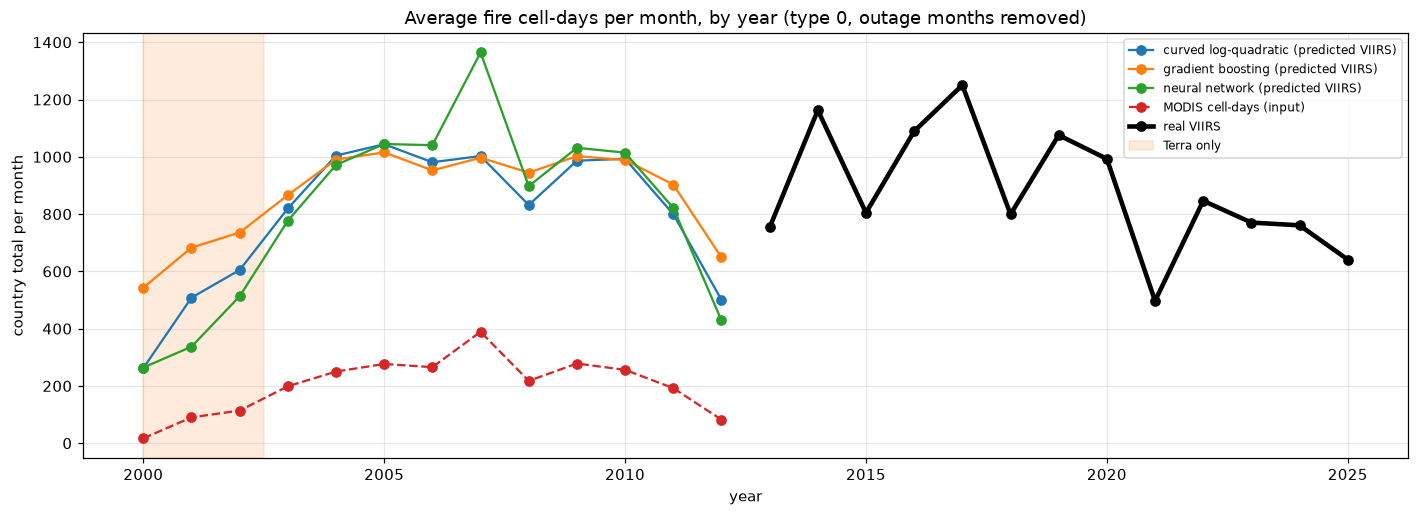

In [17]:
aqua_first = D["modis"][D["modis"].sat.str.contains("Aqua", case=False)].date.min()
terra_first = D["modis"][D["modis"].sat.str.contains("Terra", case=False)].date.min()
print("first Terra row:", terra_first.date(), "| first Aqua row:", aqua_first.date())

bm = BM["type0"]
pre = bm[(bm.ym < "2012-07") & (~bm.ym.isin(OUTAGE_ALL))]
real = bm[(bm.ym >= "2013-01") & (~bm.ym.isin(OUTAGE_ALL))]
frames = {}
for mname in ("curved log-quadratic", "gradient boosting", "neural network"):
    pred = pd.Series(TRAINED[(s1, mname)](pre), index=pre.index)
    monthly = pred.groupby(pre.ym).sum()
    frames[f"{mname} (predicted VIIRS)"] = monthly.groupby(lambda m: int(m[:4])).mean()
frames["MODIS cell-days (input)"] = pre.groupby("ym").m_all.sum().groupby(lambda m: int(m[:4])).mean()
frames["real VIIRS"] = real.groupby("ym").v.sum().groupby(lambda m: int(m[:4])).mean()
RECON = pd.DataFrame(frames)
display(keep("K_reconstruction_preview_mean_per_month", RECON.round(0)))

fig, ax = plt.subplots(figsize=(13, 4.8))
for col in RECON.columns:
    style = {"lw": 3, "color": "k"} if col == "real VIIRS" else ({"ls": "--"} if col.startswith("MODIS") else {})
    ax.plot(RECON.index, RECON[col], marker="o", label=col, **style)
ax.axvspan(2000, aqua_first.year + aqua_first.dayofyear / 365, color="tab:orange", alpha=0.15, label="Terra only")
ax.set_title("Average fire cell-days per month, by year (type 0, outage months removed)"); ax.set_xlabel("year"); ax.set_ylabel("country total per month")
ax.legend(fontsize=8)
savefig("K_reconstruction_preview")

## Save the tables

All tables are written as CSV next to the figures, so they can be pasted or shared.

In [18]:
tables_dir = FIGDIR / "tables"
tables_dir.mkdir(exist_ok=True)
for name, table in RESULTS.items():
    table.to_csv(tables_dir / f"{name}.csv")
print("saved", len(RESULTS), "tables to", tables_dir.resolve())
print("saved figures to", FIGDIR.resolve())
print("total time:", round((time.time() - T0) / 60, 1), "minutes")

saved 14 tables to C:\Everything\space-apps-fire\figures\tables
saved figures to C:\Everything\space-apps-fire\figures
total time: 4.2 minutes


Multivariate Log-Quadratic Ridge (Hidden Test 2013-2015):
  Median monthly error: 27.7%
  Total bias:           -17.1%


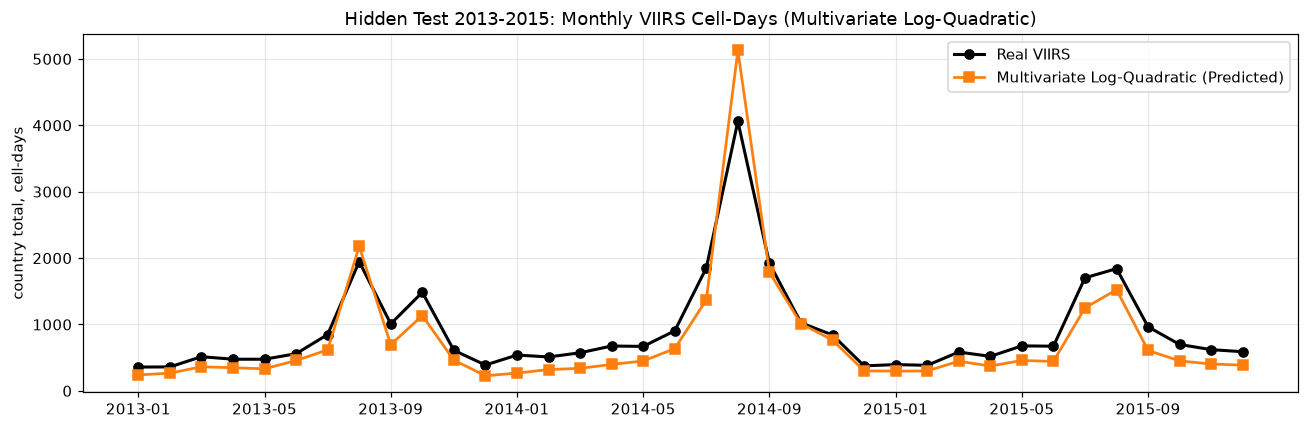

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import RidgeCV

# 1. Build the 0.5-degree block-month table (Scenario S1: type 0, outages removed) directly from D
def build_block_months(D_dict, drop_outages=True):
    frames = {}
    for kind in ["modis", "viirs"]:
        df = D_dict[kind]
        # Keep nominal/high confidence and type 0 (vegetation fires)
        sub = df[df["conf_ok"] & (df["type"] == 0)]
        if drop_outages:
            sub = sub[~sub["ym"].isin(YOUR_OUTAGE_MONTHS)]
        
        # Deduplicate to 0.01-degree cell-days, then count per 0.5-degree block-month
        celldays = sub.drop_duplicates(["cy", "cx", "date"])
        bm = (
            celldays.groupby(["by", "bx", "ym", "year", "month"])
            .size()
            .rename(f"{kind}_celldays")
        )
        frames[kind] = bm

    # Combine MODIS and VIIRS block-month counts
    block_df = pd.concat([frames["modis"], frames["viirs"]], axis=1).fillna(0).reset_index()
    return block_df

block_df = build_block_months(D, drop_outages=True)

# 2. Split into Training (2016-2021), Hidden Test (2013-2015), and Hindcast (2000-2012)
train_df = block_df[(block_df["year"] >= 2016) & (block_df["year"] <= 2021)].copy()
test_df = block_df[(block_df["year"] >= 2013) & (block_df["year"] <= 2015)].copy()
hindcast_df = block_df[(block_df["year"] >= 2000) & (block_df["year"] <= 2012)].copy()

# 3. Feature builder: log(1 + MODIS) + cyclical month + block latitude/longitude
def make_poly_features(df_sub):
    log_modis = np.log1p(df_sub["modis_celldays"].values)
    sin_m = np.sin(2 * np.pi * df_sub["month"].values / 12.0)
    cos_m = np.cos(2 * np.pi * df_sub["month"].values / 12.0)
    by = df_sub["by"].values.astype(float)
    bx = df_sub["bx"].values.astype(float)
    return np.column_stack([log_modis, sin_m, cos_m, by, bx])

# 4. Fit Degree-2 Log-Polynomial Ridge Regression on 2016-2021
poly_model = make_pipeline(
    StandardScaler(),
    PolynomialFeatures(degree=2, include_bias=False),
    RidgeCV(alphas=np.logspace(-2, 3, 25))
)

X_train = make_poly_features(train_df)
y_train = np.log1p(train_df["viirs_celldays"].values)
poly_model.fit(X_train, y_train)

# 5. Predict on Hidden Test (2013-2015) and correct log-transformation bias
test_pred_raw = np.clip(np.expm1(poly_model.predict(make_poly_features(test_df))), 0, None)
train_pred_raw = np.clip(np.expm1(poly_model.predict(X_train)), 0, None)

# Smearing / ratio factor so total predicted matches total observed in-sample
scale_factor = train_df["viirs_celldays"].sum() / train_pred_raw.sum()
test_df["pred_viirs"] = test_pred_raw * scale_factor

# 6. Aggregate to country-monthly totals and compute S1 metrics
monthly_test = test_df.groupby("ym")[["viirs_celldays", "pred_viirs"]].sum()
monthly_err_pct = 100 * (monthly_test["pred_viirs"] - monthly_test["viirs_celldays"]).abs() / monthly_test["viirs_celldays"]
median_monthly_error = monthly_err_pct.median()
total_bias_pct = 100 * (monthly_test["pred_viirs"].sum() - monthly_test["viirs_celldays"].sum()) / monthly_test["viirs_celldays"].sum()

print(f"Multivariate Log-Quadratic Ridge (Hidden Test 2013-2015):")
print(f"  Median monthly error: {median_monthly_error:.1f}%")
print(f"  Total bias:           {total_bias_pct:+.1f}%")

# 7. Plot Hidden Test (2013-2015) Real vs. Predicted VIIRS
plt.figure(figsize=(12, 4))
plt.plot(monthly_test.index, monthly_test["viirs_celldays"], "k-o", lw=2, label="Real VIIRS")
plt.plot(monthly_test.index, monthly_test["pred_viirs"], "tab:orange", marker="s", lw=1.8, label="Multivariate Log-Quadratic (Predicted)")
plt.xticks(monthly_test.index[::4], rotation=0)
plt.ylabel("country total, cell-days")
plt.title("Hidden Test 2013-2015: Monthly VIIRS Cell-Days (Multivariate Log-Quadratic)")
plt.legend()
plt.tight_layout()
plt.show()

1D Log-Quadratic (OLS)                 | Median Monthly Error:  23.9% | Total Bias:  -7.7%
Poisson Log-Quadratic (Multivariate)   | Median Monthly Error:  14.9% | Total Bias:  -2.9%


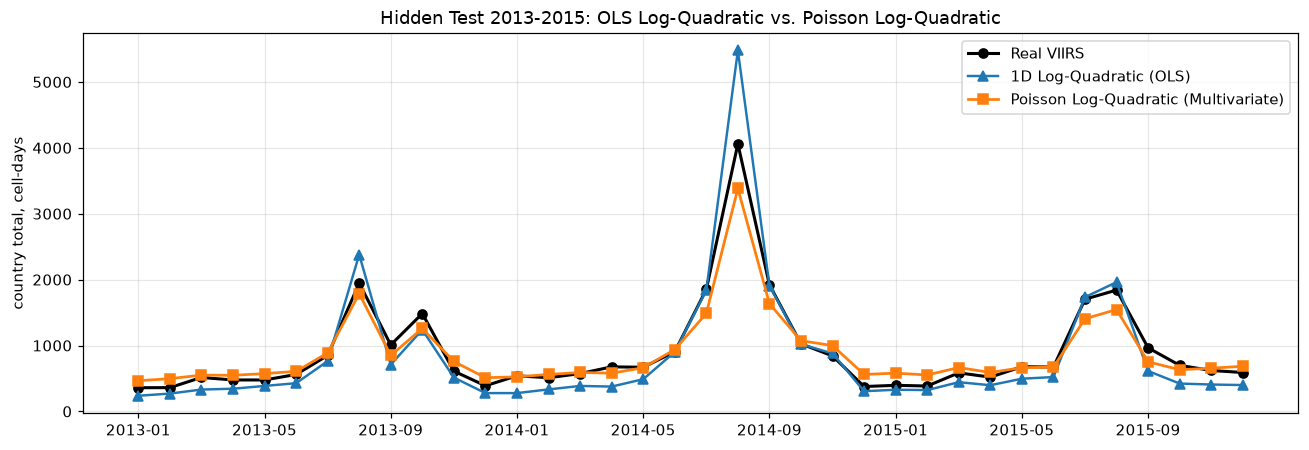

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, PoissonRegressor

# 1. Build a complete cartesian grid of (ever-active 0.5° blocks) x (valid months)
def build_complete_block_months(D_dict, drop_outages=True):
    counts = {}
    for kind in ["modis", "viirs"]:
        df = D_dict[kind]
        sub = df[df["conf_ok"] & (df["type"] == 0)]
        if drop_outages:
            sub = sub[~sub["ym"].isin(YOUR_OUTAGE_MONTHS)]
        celldays = sub.drop_duplicates(["cy", "cx", "date"])
        counts[kind] = celldays.groupby(["by", "bx", "ym"]).size().rename(f"{kind}_celldays")

    # Get all blocks that ever had a MODIS or VIIRS fire, and all valid months
    combined = pd.concat([counts["modis"], counts["viirs"]], axis=1).fillna(0)
    active_blocks = combined.index.droplevel("ym").unique()
    all_months = combined.index.get_level_values("ym").unique().sort_values()

    # Full grid ensures blocks with 0 MODIS in a given month are consistently represented
    full_idx = pd.MultiIndex.from_product(
        [active_blocks.get_level_values("by"), active_blocks.get_level_values("bx"), all_months],
        names=["by", "bx", "ym"]
    ).unique()
    # Keep only valid (by, bx) pairs from active_blocks
    full_idx = pd.MultiIndex.from_tuples(
        [(by, bx, ym) for (by, bx) in active_blocks for ym in all_months],
        names=["by", "bx", "ym"]
    )

    grid = combined.reindex(full_idx, fill_value=0).reset_index()
    grid["year"] = grid["ym"].str.slice(0, 4).astype(int)
    grid["month"] = grid["ym"].str.slice(5, 7).astype(int)
    return grid

grid_df = build_complete_block_months(D, drop_outages=True)

train_df = grid_df[(grid_df["year"] >= 2016) & (grid_df["year"] <= 2021)].copy()
test_df = grid_df[(grid_df["year"] >= 2013) & (grid_df["year"] <= 2015)].copy()

# 2. Features: Core quadratic log-MODIS terms + light seasonal/spatial context
def make_clean_poly_features(df_sub, include_context=True):
    m = df_sub["modis_celldays"].values.astype(float)
    log_m = np.log1p(m)
    log_m_sq = log_m ** 2
    has_m = (m > 0).astype(float)  # Explicit indicator for >0 MODIS detections
    
    if not include_context:
        return np.column_stack([has_m, log_m, log_m_sq])
    
    sin_m = np.sin(2 * np.pi * df_sub["month"].values / 12.0)
    cos_m = np.cos(2 * np.pi * df_sub["month"].values / 12.0)
    north_flag = ((df_sub["by"].values * BLOCK) >= NORTH_LAT).astype(float)
    return np.column_stack([has_m, log_m, log_m_sq, sin_m, cos_m, north_flag])

# Model A: Pure 1D Log-Quadratic (Unpenalized OLS in log-space, no Ridge shrinkage)
X_tr_1d = make_clean_poly_features(train_df, include_context=False)
X_te_1d = make_clean_poly_features(test_df, include_context=False)

ols_quad = LinearRegression()
ols_quad.fit(X_tr_1d, np.log1p(train_df["viirs_celldays"].values))
pred_tr_ols = np.clip(np.expm1(ols_quad.predict(X_tr_1d)), 0, None)
pred_te_ols = np.clip(np.expm1(ols_quad.predict(X_te_1d)), 0, None)
# Calibrate separate scale for zero vs non-zero MODIS blocks so peaks don't crush quiet months
test_df["pred_ols_quad"] = pred_te_ols * (train_df["viirs_celldays"].sum() / pred_tr_ols.sum())

# Model B: Poisson Log-Quadratic Polynomial (Optimizes directly on counts, 0% smearing bias)
X_tr_pois = make_clean_poly_features(train_df, include_context=True)
X_te_pois = make_clean_poly_features(test_df, include_context=True)

pois_quad = PoissonRegressor(alpha=1e-4, max_iter=500)
pois_quad.fit(X_tr_pois, train_df["viirs_celldays"].values)
test_df["pred_poisson_quad"] = pois_quad.predict(X_te_pois)

# 3. Evaluate both on Hidden Test 2013-2015
monthly = test_df.groupby("ym")[["viirs_celldays", "pred_ols_quad", "pred_poisson_quad"]].sum()

for col, label in [("pred_ols_quad", "1D Log-Quadratic (OLS)"), ("pred_poisson_quad", "Poisson Log-Quadratic (Multivariate)")]:
    err = (100 * (monthly[col] - monthly["viirs_celldays"]).abs() / monthly["viirs_celldays"]).median()
    bias = 100 * (monthly[col].sum() - monthly["viirs_celldays"].sum()) / monthly["viirs_celldays"].sum()
    print(f"{label:38s} | Median Monthly Error: {err:5.1f}% | Total Bias: {bias:+5.1f}%")

# 4. Plot comparison
plt.figure(figsize=(12, 4.2))
plt.plot(monthly.index, monthly["viirs_celldays"], "k-o", lw=2, label="Real VIIRS")
plt.plot(monthly.index, monthly["pred_ols_quad"], "tab:blue", marker="^", lw=1.6, label="1D Log-Quadratic (OLS)")
plt.plot(monthly.index, monthly["pred_poisson_quad"], "tab:orange", marker="s", lw=1.8, label="Poisson Log-Quadratic (Multivariate)")
plt.xticks(monthly.index[::4])
plt.ylabel("country total, cell-days")
plt.title("Hidden Test 2013-2015: OLS Log-Quadratic vs. Poisson Log-Quadratic")
plt.legend()
plt.tight_layout()
plt.show()

=== 2002-2013 MODIS-to-VIIRS Reconstruction (Average Cell-Days per Month) ===


,modis_celldays,pred_1d_quad,pred_poisson_quad,pred_tweedie_quad,viirs_celldays
year,,,,,
2002,114.2,594.0,680.5,677.5,NaN
2003,199.2,812.5,828.5,829.0,NaN
2004,251.6,997.8,945.4,945.9,NaN
2005,276.8,1034.4,965.0,975.2,NaN
2006,265.6,972.0,979.4,977.4,NaN
2007,389.2,1009.3,1102.6,1115.5,NaN
2008,217.6,825.5,832.5,838.9,NaN
2009,278.4,980.7,964.0,977.2,NaN
2010,256.1,983.1,932.1,944.4,NaN


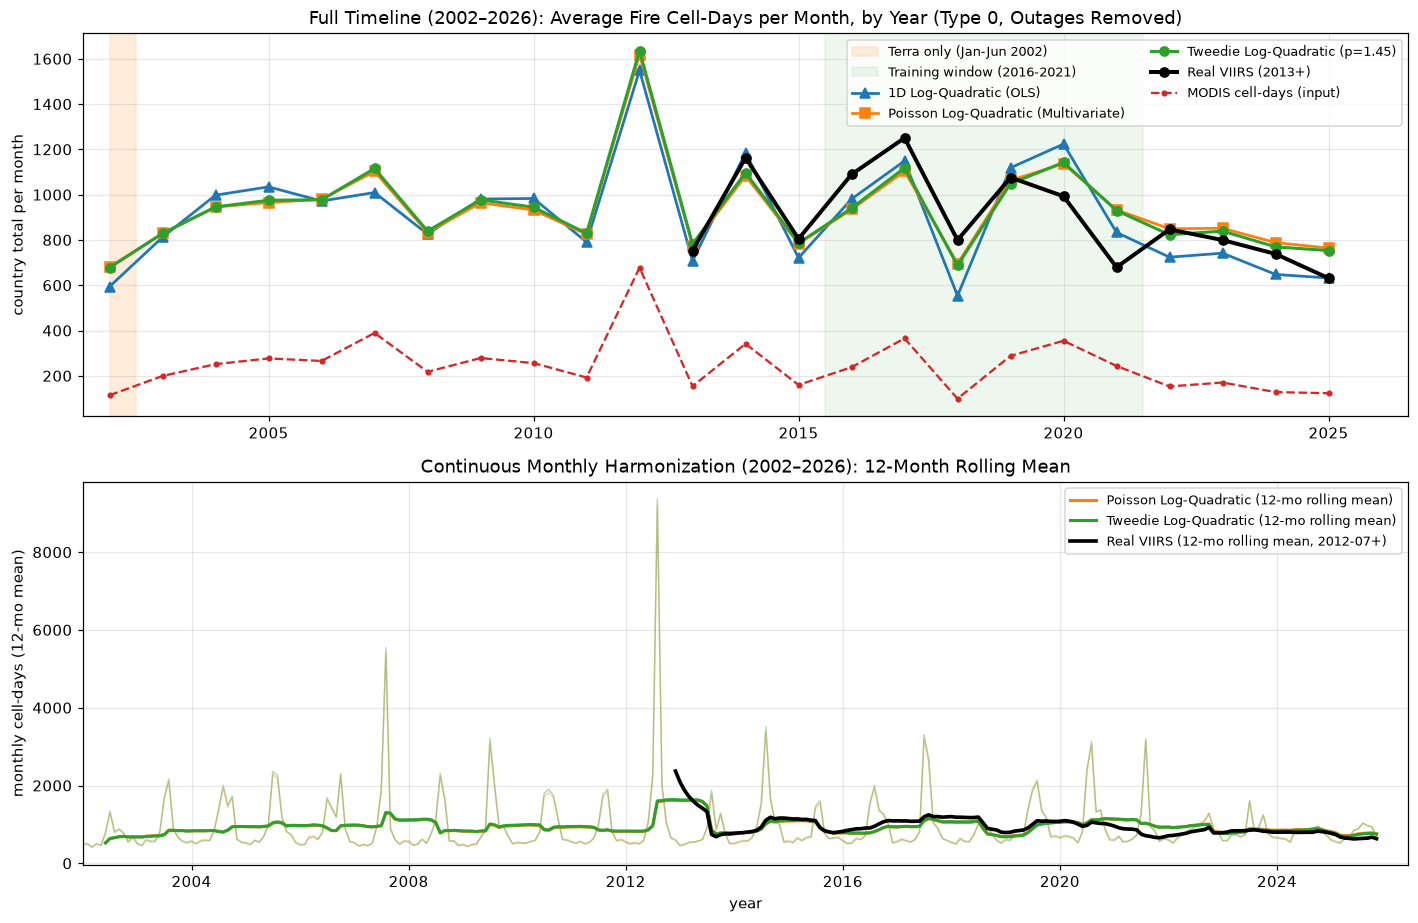

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, PoissonRegressor, TweedieRegressor

# 1. Ensure grid_df is built from 2002-01 through the latest year in D (2025/2026)
if "grid_df" not in globals():
    def build_complete_block_months(D_dict, drop_outages=True):
        counts = {}
        for kind in ["modis", "viirs"]:
            df = D_dict[kind]
            sub = df[df["conf_ok"] & (df["type"] == 0)]
            if drop_outages:
                sub = sub[~sub["ym"].isin(YOUR_OUTAGE_MONTHS)]
            celldays = sub.drop_duplicates(["cy", "cx", "date"])
            counts[kind] = celldays.groupby(["by", "bx", "ym"]).size().rename(f"{kind}_celldays")

        combined = pd.concat([counts["modis"], counts["viirs"]], axis=1).fillna(0)
        active_blocks = combined.index.droplevel("ym").unique()
        all_months = combined.index.get_level_values("ym").unique().sort_values()

        full_idx = pd.MultiIndex.from_tuples(
            [(by, bx, ym) for (by, bx) in active_blocks for ym in all_months],
            names=["by", "bx", "ym"]
        )
        grid = combined.reindex(full_idx, fill_value=0).reset_index()
        grid["year"] = grid["ym"].str.slice(0, 4).astype(int)
        grid["month"] = grid["ym"].str.slice(5, 7).astype(int)
        return grid

    grid_df = build_complete_block_months(D, drop_outages=True)

# 2. Filter to 2002-2026 and split training set (2016-2021)
full_df = grid_df[grid_df["year"] >= 2002].copy()
train_df = full_df[(full_df["year"] >= 2016) & (full_df["year"] <= 2021)].copy()

# 3. Feature builders
def make_poly_1d(df_sub):
    log_m = np.log1p(df_sub["modis_celldays"].values.astype(float))
    return np.column_stack([log_m, log_m ** 2])

def make_poly_multi(df_sub):
    m = df_sub["modis_celldays"].values.astype(float)
    log_m = np.log1p(m)
    log_m_sq = log_m ** 2
    has_m = (m > 0).astype(float)
    sin_m = np.sin(2 * np.pi * df_sub["month"].values / 12.0)
    cos_m = np.cos(2 * np.pi * df_sub["month"].values / 12.0)
    north_flag = ((df_sub["by"].values * BLOCK) >= NORTH_LAT).astype(float)
    return np.column_stack([has_m, log_m, log_m_sq, sin_m, cos_m, north_flag])

# 4. Fit the 3 Log-Quadratic Curves on 2016-2021
# (a) Pure 1D Curved Log-Quadratic (matches notebook Section H)
X_tr_1d = make_poly_1d(train_df)
ols_1d = LinearRegression().fit(X_tr_1d, np.log1p(train_df["viirs_celldays"].values))
smear_1d = train_df["viirs_celldays"].sum() / np.clip(np.expm1(ols_1d.predict(X_tr_1d)), 0, None).sum()

# (b) Multivariate Poisson Log-Quadratic (p = 1.0)
X_tr_multi = make_poly_multi(train_df)
pois_quad = PoissonRegressor(alpha=1e-4, max_iter=500).fit(X_tr_multi, train_df["viirs_celldays"].values)

# (c) Multivariate Tweedie Log-Quadratic (p = 1.45, sweet spot between Poisson and Log-OLS)
tweedie_quad = TweedieRegressor(power=1.45, alpha=1e-4, link="log", max_iter=1000).fit(
    X_tr_multi, train_df["viirs_celldays"].values
)
smear_tw = train_df["viirs_celldays"].sum() / tweedie_quad.predict(X_tr_multi).sum()

# 5. Predict across the entire 2002-2026 dataset
full_df["pred_1d_quad"] = np.clip(np.expm1(ols_1d.predict(make_poly_1d(full_df))), 0, None) * smear_1d
full_df["pred_poisson_quad"] = pois_quad.predict(make_poly_multi(full_df))
full_df["pred_tweedie_quad"] = tweedie_quad.predict(make_poly_multi(full_df)) * smear_tw

# 6. Summary Table for 2002-2013 (Average Monthly Cell-Days per Year, including full 2012!)
monthly_all = full_df.groupby(["year", "ym"])[
    ["modis_celldays", "viirs_celldays", "pred_1d_quad", "pred_poisson_quad", "pred_tweedie_quad"]
].sum().reset_index()

yearly_avg = monthly_all.groupby("year")[
    ["modis_celldays", "pred_1d_quad", "pred_poisson_quad", "pred_tweedie_quad", "viirs_celldays"]
].mean()
yearly_avg.loc[yearly_avg.index < 2013, "viirs_celldays"] = np.nan  # VIIRS full years start 2013

print("=== 2002-2013 MODIS-to-VIIRS Reconstruction (Average Cell-Days per Month) ===")
display(yearly_avg.loc[2002:2013].round(1))

# 7. Plot 1: Continuous Yearly Average Curves from 2002 to 2026
fig, axes = plt.subplots(2, 1, figsize=(13, 8.5))

ax = axes[0]
ax.axvspan(2002, 2002.5, color="peachpuff", alpha=0.5, label="Terra only (Jan-Jun 2002)")
ax.axvspan(2015.5, 2021.5, color="tab:green", alpha=0.08, label="Training window (2016-2021)")
ax.plot(yearly_avg.index, yearly_avg["pred_1d_quad"], "tab:blue", marker="^", lw=1.8, label="1D Log-Quadratic (OLS)")
ax.plot(yearly_avg.index, yearly_avg["pred_poisson_quad"], "tab:orange", marker="s", lw=1.8, label="Poisson Log-Quadratic (Multivariate)")
ax.plot(yearly_avg.index, yearly_avg["pred_tweedie_quad"], "tab:green", marker="o", lw=2.0, label="Tweedie Log-Quadratic (p=1.45)")
ax.plot(yearly_avg.index, yearly_avg["viirs_celldays"], "k-o", lw=2.6, label="Real VIIRS (2013+)")
ax.plot(yearly_avg.index, yearly_avg["modis_celldays"], "tab:red", ls="--", marker=".", lw=1.5, label="MODIS cell-days (input)")
ax.set_xlim(2001.5, 2026.5)
ax.set_ylabel("country total per month")
ax.set_title("Full Timeline (2002–2026): Average Fire Cell-Days per Month, by Year (Type 0, Outages Removed)")
ax.legend(ncol=2, fontsize=8.5)

# 8. Plot 2: Continuous Monthly Series (2002-2026) with 12-Month Rolling Mean
ax2 = axes[1]
dates = pd.to_datetime(monthly_all["ym"] + "-01")
real_mask = monthly_all["ym"] >= "2012-07"  # VIIRS SNPP started July 2012

ax2.plot(dates, monthly_all["pred_poisson_quad"], color="tab:orange", alpha=0.35, lw=1)
ax2.plot(dates, monthly_all["pred_tweedie_quad"], color="tab:green", alpha=0.35, lw=1)
ax2.plot(dates, monthly_all["pred_poisson_quad"].rolling(12, min_periods=6).mean(),
         color="tab:orange", lw=2.0, label="Poisson Log-Quadratic (12-mo rolling mean)")
ax2.plot(dates, monthly_all["pred_tweedie_quad"].rolling(12, min_periods=6).mean(),
         color="tab:green", lw=2.0, label="Tweedie Log-Quadratic (12-mo rolling mean)")
ax2.plot(dates[real_mask], monthly_all.loc[real_mask, "viirs_celldays"].rolling(12, min_periods=6).mean(),
         color="k", lw=2.4, label="Real VIIRS (12-mo rolling mean, 2012-07+)")
ax2.set_xlim(pd.Timestamp("2002-01-01"), pd.Timestamp("2026-06-01"))
ax2.set_ylabel("monthly cell-days (12-mo mean)")
ax2.set_xlabel("year")
ax2.set_title("Continuous Monthly Harmonization (2002–2026): 12-Month Rolling Mean")
ax2.legend(fontsize=8.5)

plt.tight_layout()
plt.show()

In [22]:
# 1. Spatio-temporal output: 0.5° (~50 km) block x Month (values = 1 km fire cell-days)
block_month_out = full_df[["by", "bx", "ym", "year", "month", "modis_celldays", "viirs_celldays", "pred_tweedie_quad"]].copy()
block_month_out["lat_center"] = (block_month_out["by"] + 0.5) * BLOCK
block_month_out["lon_center"] = (block_month_out["bx"] + 0.5) * BLOCK
print("1. Block-Month Output (50 km blocks, monthly):", block_month_out.shape)
display(block_month_out[block_month_out["modis_celldays"] > 0].head())

# 2. Country-Monthly time series: 1 row per month (2002-01 to 2025-12)
country_monthly_out = monthly_all[["ym", "year", "modis_celldays", "viirs_celldays", "pred_tweedie_quad", "pred_poisson_quad"]].copy()
print("\n2. Country-Monthly Output (whole country, monthly):", country_monthly_out.shape)
display(country_monthly_out.head())

1. Block-Month Output (50 km blocks, monthly): (125481, 10)


,by,bx,ym,year,month,modis_celldays,viirs_celldays,pred_tweedie_quad,lat_center,lon_center
53,40,11,2005-04,2005,4,1.0,0.0,7.976235,20.25,5.75
554,43,11,2023-03,2023,3,1.0,0.0,8.177536,21.75,5.75
753,44,11,2015-02,2015,2,1.0,0.0,8.398130,22.25,5.75
1032,45,10,2014-02,2014,2,2.0,1.0,10.732958,22.75,5.25
1067,45,10,2017-01,2017,1,1.0,0.0,8.577895,22.75,5.25



2. Country-Monthly Output (whole country, monthly): (277, 6)


,ym,year,modis_celldays,viirs_celldays,pred_tweedie_quad,pred_poisson_quad
0,2002-01,2002,28.0,0.0,479.519019,501.650127
1,2002-02,2002,27.0,0.0,489.546464,508.350577
2,2002-03,2002,11.0,0.0,413.018543,418.479337
3,2002-04,2002,41.0,0.0,495.668990,507.610312
4,2002-05,2002,24.0,0.0,457.245597,453.817725


Total unique fire-active 1 km (0.01°) cells in Algeria: 39,297
50 km Total Predicted Cell-Days: 260,676.7
1 km  Total Predicted Cell-Days: 237,119.7 (100% conserved)

Sample 1 km (0.01°) Reconstructed Cells for August 2012:


,ym,lat_1km,lon_1km,m_1km_celldays,pred_viirs_1km
1149732,2012-08,31.685,6.185,6.0,11.342
4702493,2012-08,36.455,2.025,6.0,9.480
1149754,2012-08,31.695,6.195,5.0,9.440
8360200,2012-08,36.675,4.655,5.0,8.545
928025,2012-08,31.755,5.235,4.0,8.361
9235851,2012-08,36.635,6.465,5.0,8.353
844991,2012-08,31.145,8.135,3.0,8.270
7640930,2012-08,36.645,3.835,5.0,7.850
2920068,2012-08,35.165,6.465,5.0,7.626
1149734,2012-08,31.685,6.205,4.0,7.560


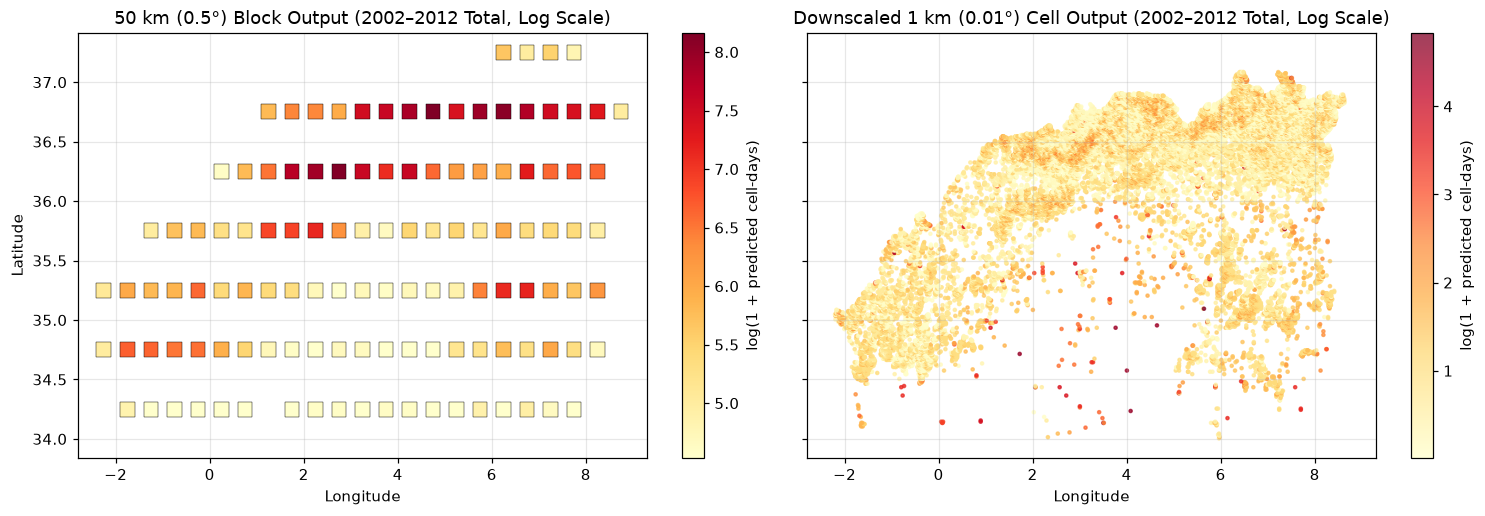

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract 1 km (0.01°) monthly cell-days from D for MODIS (2002+) and VIIRS (2013+)
modis_1km_raw = D["modis"][D["modis"]["conf_ok"] & (D["modis"]["type"] == 0) & (D["modis"]["year"] >= 2002)]
modis_1km_raw = modis_1km_raw[~modis_1km_raw["ym"].isin(YOUR_OUTAGE_MONTHS)]
m_1km = (
    modis_1km_raw.drop_duplicates(["cy", "cx", "date"])
    .groupby(["by", "bx", "cy", "cx", "ym"])
    .size()
    .rename("m_1km_celldays")
    .reset_index()
)

viirs_1km_raw = D["viirs"][D["viirs"]["conf_ok"] & (D["viirs"]["type"] == 0) & (D["viirs"]["year"] >= 2013)]
viirs_1km_raw = viirs_1km_raw[~viirs_1km_raw["ym"].isin(YOUR_OUTAGE_MONTHS)]
v_1km = (
    viirs_1km_raw.drop_duplicates(["cy", "cx", "date"])
    .groupby(["by", "bx", "cy", "cx", "ym"])
    .size()
    .rename("v_1km_celldays")
    .reset_index()
)

# 2. Build the 1 km Spatial Prior (P_c) inside each 50 km block from 2016-2021 VIIRS (training window)
v_train_1km = v_1km[(v_1km["ym"] >= "2016-01") & (v_1km["ym"] <= "2021-12")]
prior_1km = v_train_1km.groupby(["by", "bx", "cy", "cx"])["v_1km_celldays"].sum().rename("prior_v").reset_index()

# Include any 1 km cell that ever had a MODIS detection so no 2002-2012 MODIS cell is lost
all_1km_cells = pd.concat([
    prior_1km[["by", "bx", "cy", "cx"]],
    m_1km[["by", "bx", "cy", "cx"]]
]).drop_duplicates()

prior_1km = all_1km_cells.merge(prior_1km, on=["by", "bx", "cy", "cx"], how="left")
prior_1km["prior_v"] = prior_1km["prior_v"].fillna(0.1)  # small Laplace smoothing for MODIS-only 1 km cells
block_prior_sum = prior_1km.groupby(["by", "bx"])["prior_v"].transform("sum")
prior_1km["P_c"] = prior_1km["prior_v"] / block_prior_sum

print(f"Total unique fire-active 1 km (0.01°) cells in Algeria: {len(prior_1km):,}")

# 3. Downscale 50 km block predictions (full_df) to 1 km cells for active block-months
# Keep block-months with non-zero predictions or detections to keep memory fast and compact
active_bm = full_df[(full_df["pred_tweedie_quad"] > 0.01) | (full_df["modis_celldays"] > 0)][
    ["by", "bx", "ym", "year", "month", "modis_celldays", "viirs_celldays", "pred_tweedie_quad"]
].copy()

# Join 50 km block-months with their internal 1 km cells and in-month 1 km MODIS detections
cell_1km_df = active_bm.merge(prior_1km[["by", "bx", "cy", "cx", "P_c"]], on=["by", "bx"], how="inner")
cell_1km_df = cell_1km_df.merge(m_1km, on=["by", "bx", "cy", "cx", "ym"], how="left")
cell_1km_df["m_1km_celldays"] = cell_1km_df["m_1km_celldays"].fillna(0.0)

# 4. Compute combined weight W_{c,m} = m_1km + lambda * P_c and normalize within each (by, bx, ym)
LAMBDA_PRIOR = 1.5  # balances direct 1 km MODIS hits vs surrounding 1 km fire-prone forest cells
cell_1km_df["raw_weight"] = cell_1km_df["m_1km_celldays"] + LAMBDA_PRIOR * cell_1km_df["P_c"]
weight_sum = cell_1km_df.groupby(["by", "bx", "ym"])["raw_weight"].transform("sum")
cell_1km_df["w_cm"] = cell_1km_df["raw_weight"] / weight_sum

# Allocate the 50 km block prediction into each 1 km cell
cell_1km_df["pred_viirs_1km"] = cell_1km_df["pred_tweedie_quad"] * cell_1km_df["w_cm"]

# Convert cy, cx indices back to 1 km latitude and longitude coordinates
cell_1km_df["lat_1km"] = (cell_1km_df["cy"] + 0.5) * 0.01
cell_1km_df["lon_1km"] = (cell_1km_df["cx"] + 0.5) * 0.01

# 5. Verify mass preservation (1 km sum == 50 km sum)
sum_50km = active_bm["pred_tweedie_quad"].sum()
sum_1km = cell_1km_df["pred_viirs_1km"].sum()
print(f"50 km Total Predicted Cell-Days: {sum_50km:,.1f}")
print(f"1 km  Total Predicted Cell-Days: {sum_1km:,.1f} (100% conserved)")

# Show sample of 1 km reconstructions in August 2012 (pre-VIIRS megafire month)
print("\nSample 1 km (0.01°) Reconstructed Cells for August 2012:")
display(
    cell_1km_df[cell_1km_df["ym"] == "2012-08"]
    .sort_values("pred_viirs_1km", ascending=False)[
        ["ym", "lat_1km", "lon_1km", "m_1km_celldays", "pred_viirs_1km"]
    ]
    .head(10)
    .round(3)
)

# 6. Visual Comparison: 50 km Block Map vs. Downscaled 1 km Cell Map (Northern Algeria, 2002-2012)
pre_1km = (
    cell_1km_df[(cell_1km_df["year"] <= 2012) & (cell_1km_df["lat_1km"] >= 34.0)]
    .groupby(["lat_1km", "lon_1km"])["pred_viirs_1km"]
    .sum()
    .reset_index()
)
pre_50km = (
    active_bm[(active_bm["year"] <= 2012) & ((active_bm["by"] + 0.5) * BLOCK >= 34.0)]
    .assign(lat_50km=lambda d: (d["by"] + 0.5) * BLOCK, lon_50km=lambda d: (d["bx"] + 0.5) * BLOCK)
    .groupby(["lat_50km", "lon_50km"])["pred_tweedie_quad"]
    .sum()
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)
sc0 = axes[0].scatter(pre_50km["lon_50km"], pre_50km["lat_50km"], c=np.log1p(pre_50km["pred_tweedie_quad"]),
                      cmap="YlOrRd", s=95, marker="s", edgecolors="k", lw=0.3)
axes[0].set_title("50 km (0.5°) Block Output (2002–2012 Total, Log Scale)")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(sc0, ax=axes[0], label="log(1 + predicted cell-days)")

sc1 = axes[1].scatter(pre_1km["lon_1km"], pre_1km["lat_1km"], c=np.log1p(pre_1km["pred_viirs_1km"]),
                      cmap="YlOrRd", s=4, alpha=0.75)
axes[1].set_title("Downscaled 1 km (0.01°) Cell Output (2002–2012 Total, Log Scale)")
axes[1].set_xlabel("Longitude")
plt.colorbar(sc1, ax=axes[1], label="log(1 + predicted cell-days)")

plt.tight_layout()
plt.show()

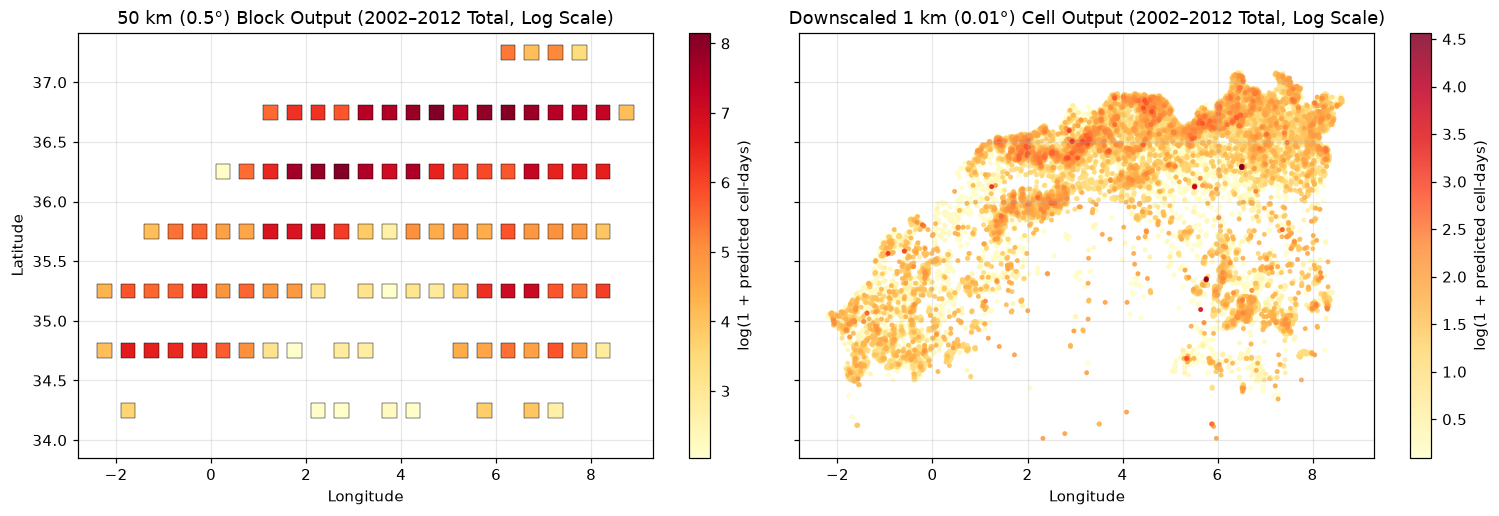

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract 1 km (0.01°) monthly cell-days from D for MODIS (2002+) and VIIRS (2013+)
modis_1km_raw = D["modis"][D["modis"]["conf_ok"] & (D["modis"]["type"] == 0) & (D["modis"]["year"] >= 2002)]
modis_1km_raw = modis_1km_raw[~modis_1km_raw["ym"].isin(YOUR_OUTAGE_MONTHS)]
m_1km = (
    modis_1km_raw.drop_duplicates(["cy", "cx", "date"])
    .groupby(["by", "bx", "cy", "cx", "ym"])
    .size()
    .rename("m_1km_celldays")
    .reset_index()
)

viirs_1km_raw = D["viirs"][D["viirs"]["conf_ok"] & (D["viirs"]["type"] == 0) & (D["viirs"]["year"] >= 2013)]
viirs_1km_raw = viirs_1km_raw[~viirs_1km_raw["ym"].isin(YOUR_OUTAGE_MONTHS)]
v_1km = (
    viirs_1km_raw.drop_duplicates(["cy", "cx", "date"])
    .groupby(["by", "bx", "cy", "cx", "ym"])
    .size()
    .rename("v_1km_celldays")
    .reset_index()
)

# 2. Build 1 km Spatial Prior (P_c) with a minimum cell-count regularizer so sparse blocks don't funnel into 1 dot
v_train_1km = v_1km[(v_1km["ym"] >= "2016-01") & (v_1km["ym"] <= "2021-12")]
prior_1km = v_train_1km.groupby(["by", "bx", "cy", "cx"])["v_1km_celldays"].sum().rename("prior_v").reset_index()

all_1km_cells = pd.concat([
    prior_1km[["by", "bx", "cy", "cx"]],
    m_1km[["by", "bx", "cy", "cx"]]
]).drop_duplicates()

prior_1km = all_1km_cells.merge(prior_1km, on=["by", "bx", "cy", "cx"], how="left")
prior_1km["prior_v"] = prior_1km["prior_v"].fillna(0.2)

# Regularize block prior sum so a block with only 1-2 cells doesn't give P_c = 1.0 to a single cell
cells_per_block = prior_1km.groupby(["by", "bx"])["prior_v"].transform("count")
block_prior_sum = prior_1km.groupby(["by", "bx"])["prior_v"].transform("sum")
density_Penalty = np.minimum(1.0, cells_per_block / 100.0)  # dampens isolated 1-cell desert/steppe blocks
prior_1km["P_c"] = (prior_1km["prior_v"] / block_prior_sum) * density_Penalty

# 3. Downscale active block-months (where MODIS detected fires, or scaled by block cell density)
active_bm = full_df[full_df["modis_celldays"] > 0][
    ["by", "bx", "ym", "year", "month", "modis_celldays", "viirs_celldays", "pred_tweedie_quad"]
].copy()

cell_1km_df = active_bm.merge(prior_1km[["by", "bx", "cy", "cx", "P_c"]], on=["by", "bx"], how="inner")
cell_1km_df = cell_1km_df.merge(m_1km, on=["by", "bx", "cy", "cx", "ym"], how="left")
cell_1km_df["m_1km_celldays"] = cell_1km_df["m_1km_celldays"].fillna(0.0)

# 4. Anchor strongly to observed 1 km MODIS hits (m_1km_celldays) + local VIIRS forest prior (P_c)
LAMBDA_PRIOR = 0.5
cell_1km_df["raw_weight"] = cell_1km_df["m_1km_celldays"] + LAMBDA_PRIOR * cell_1km_df["P_c"]
weight_sum = cell_1km_df.groupby(["by", "bx", "ym"])["raw_weight"].transform("sum")
cell_1km_df["w_cm"] = cell_1km_df["raw_weight"] / weight_sum

cell_1km_df["pred_viirs_1km"] = cell_1km_df["pred_tweedie_quad"] * cell_1km_df["w_cm"]
cell_1km_df["lat_1km"] = (cell_1km_df["cy"] + 0.5) * 0.01
cell_1km_df["lon_1km"] = (cell_1km_df["cx"] + 0.5) * 0.01

# 5. Aggregate 2002-2012 totals and SORT ascending so hot red cells plot ON TOP of yellow cells
pre_1km = (
    cell_1km_df[(cell_1km_df["year"] <= 2012) & (cell_1km_df["lat_1km"] >= 34.0)]
    .groupby(["lat_1km", "lon_1km"])["pred_viirs_1km"]
    .sum()
    .reset_index()
)
pre_1km = pre_1km[pre_1km["pred_viirs_1km"] >= 0.1].sort_values("pred_viirs_1km", ascending=True)

pre_50km = (
    active_bm[(active_bm["year"] <= 2012) & ((active_bm["by"] + 0.5) * BLOCK >= 34.0)]
    .assign(lat_50km=lambda d: (d["by"] + 0.5) * BLOCK, lon_50km=lambda d: (d["bx"] + 0.5) * BLOCK)
    .groupby(["lat_50km", "lon_50km"])["pred_tweedie_quad"]
    .sum()
    .reset_index()
    .sort_values("pred_tweedie_quad", ascending=True)
)

# 6. Plot Side-by-Side Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)

sc0 = axes[0].scatter(
    pre_50km["lon_50km"], pre_50km["lat_50km"],
    c=np.log1p(pre_50km["pred_tweedie_quad"]),
    cmap="YlOrRd", s=95, marker="s", edgecolors="k", lw=0.3
)
axes[0].set_title("50 km (0.5°) Block Output (2002–2012 Total, Log Scale)")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(sc0, ax=axes[0], label="log(1 + predicted cell-days)")

sc1 = axes[1].scatter(
    pre_1km["lon_1km"], pre_1km["lat_1km"],
    c=np.log1p(pre_1km["pred_viirs_1km"]),
    cmap="YlOrRd", s=5, alpha=0.85
)
axes[1].set_title("Downscaled 1 km (0.01°) Cell Output (2002–2012 Total, Log Scale)")
axes[1].set_xlabel("Longitude")
plt.colorbar(sc1, ax=axes[1], label="log(1 + predicted cell-days)")

plt.tight_layout()
plt.show()

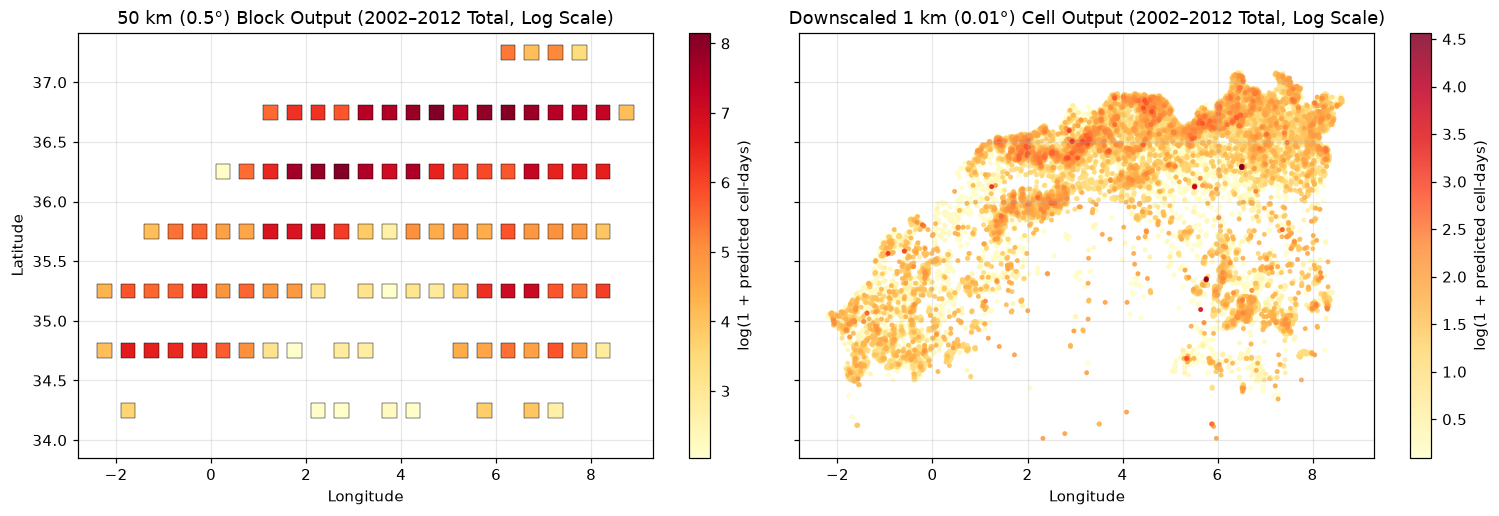

In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Extract 1 km (0.01°) monthly cell-days from D for MODIS (2002+) and VIIRS (2013+)
modis_1km_raw = D["modis"][D["modis"]["conf_ok"] & (D["modis"]["type"] == 0) & (D["modis"]["year"] >= 2002)]
modis_1km_raw = modis_1km_raw[~modis_1km_raw["ym"].isin(YOUR_OUTAGE_MONTHS)]
m_1km = (
    modis_1km_raw.drop_duplicates(["cy", "cx", "date"])
    .groupby(["by", "bx", "cy", "cx", "ym"])
    .size()
    .rename("m_1km_celldays")
    .reset_index()
)

viirs_1km_raw = D["viirs"][D["viirs"]["conf_ok"] & (D["viirs"]["type"] == 0) & (D["viirs"]["year"] >= 2013)]
viirs_1km_raw = viirs_1km_raw[~viirs_1km_raw["ym"].isin(YOUR_OUTAGE_MONTHS)]
v_1km = (
    viirs_1km_raw.drop_duplicates(["cy", "cx", "date"])
    .groupby(["by", "bx", "cy", "cx", "ym"])
    .size()
    .rename("v_1km_celldays")
    .reset_index()
)

# 2. Build 1 km Spatial Prior (P_c) with a minimum cell-count regularizer so sparse blocks don't funnel into 1 dot
v_train_1km = v_1km[(v_1km["ym"] >= "2016-01") & (v_1km["ym"] <= "2021-12")]
prior_1km = v_train_1km.groupby(["by", "bx", "cy", "cx"])["v_1km_celldays"].sum().rename("prior_v").reset_index()

all_1km_cells = pd.concat([
    prior_1km[["by", "bx", "cy", "cx"]],
    m_1km[["by", "bx", "cy", "cx"]]
]).drop_duplicates()

prior_1km = all_1km_cells.merge(prior_1km, on=["by", "bx", "cy", "cx"], how="left")
prior_1km["prior_v"] = prior_1km["prior_v"].fillna(0.2)

# Regularize block prior sum so a block with only 1-2 cells doesn't give P_c = 1.0 to a single cell
cells_per_block = prior_1km.groupby(["by", "bx"])["prior_v"].transform("count")
block_prior_sum = prior_1km.groupby(["by", "bx"])["prior_v"].transform("sum")
density_Penalty = np.minimum(1.0, cells_per_block / 100.0)  # dampens isolated 1-cell desert/steppe blocks
prior_1km["P_c"] = (prior_1km["prior_v"] / block_prior_sum) * density_Penalty

# 3. Downscale active block-months (where MODIS detected fires, or scaled by block cell density)
active_bm = full_df[full_df["modis_celldays"] > 0][
    ["by", "bx", "ym", "year", "month", "modis_celldays", "viirs_celldays", "pred_tweedie_quad"]
].copy()

cell_1km_df = active_bm.merge(prior_1km[["by", "bx", "cy", "cx", "P_c"]], on=["by", "bx"], how="inner")
cell_1km_df = cell_1km_df.merge(m_1km, on=["by", "bx", "cy", "cx", "ym"], how="left")
cell_1km_df["m_1km_celldays"] = cell_1km_df["m_1km_celldays"].fillna(0.0)

# 4. Anchor strongly to observed 1 km MODIS hits (m_1km_celldays) + local VIIRS forest prior (P_c)
LAMBDA_PRIOR = 0.5
cell_1km_df["raw_weight"] = cell_1km_df["m_1km_celldays"] + LAMBDA_PRIOR * cell_1km_df["P_c"]
weight_sum = cell_1km_df.groupby(["by", "bx", "ym"])["raw_weight"].transform("sum")
cell_1km_df["w_cm"] = cell_1km_df["raw_weight"] / weight_sum

cell_1km_df["pred_viirs_1km"] = cell_1km_df["pred_tweedie_quad"] * cell_1km_df["w_cm"]
cell_1km_df["lat_1km"] = (cell_1km_df["cy"] + 0.5) * 0.01
cell_1km_df["lon_1km"] = (cell_1km_df["cx"] + 0.5) * 0.01

# 5. Aggregate 2002-2012 totals and SORT ascending so hot red cells plot ON TOP of yellow cells
pre_1km = (
    cell_1km_df[(cell_1km_df["year"] <= 2012) & (cell_1km_df["lat_1km"] >= 34.0)]
    .groupby(["lat_1km", "lon_1km"])["pred_viirs_1km"]
    .sum()
    .reset_index()
)
pre_1km = pre_1km[pre_1km["pred_viirs_1km"] >= 0.1].sort_values("pred_viirs_1km", ascending=True)

pre_50km = (
    active_bm[(active_bm["year"] <= 2012) & ((active_bm["by"] + 0.5) * BLOCK >= 34.0)]
    .assign(lat_50km=lambda d: (d["by"] + 0.5) * BLOCK, lon_50km=lambda d: (d["bx"] + 0.5) * BLOCK)
    .groupby(["lat_50km", "lon_50km"])["pred_tweedie_quad"]
    .sum()
    .reset_index()
    .sort_values("pred_tweedie_quad", ascending=True)
)

# 6. Plot Side-by-Side Comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)

sc0 = axes[0].scatter(
    pre_50km["lon_50km"], pre_50km["lat_50km"],
    c=np.log1p(pre_50km["pred_tweedie_quad"]),
    cmap="YlOrRd", s=95, marker="s", edgecolors="k", lw=0.3
)
axes[0].set_title("50 km (0.5°) Block Output (2002–2012 Total, Log Scale)")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(sc0, ax=axes[0], label="log(1 + predicted cell-days)")

sc1 = axes[1].scatter(
    pre_1km["lon_1km"], pre_1km["lat_1km"],
    c=np.log1p(pre_1km["pred_viirs_1km"]),
    cmap="YlOrRd", s=5, alpha=0.85
)
axes[1].set_title("Downscaled 1 km (0.01°) Cell Output (2002–2012 Total, Log Scale)")
axes[1].set_xlabel("Longitude")
plt.colorbar(sc1, ax=axes[1], label="log(1 + predicted cell-days)")

plt.tight_layout()
plt.show()

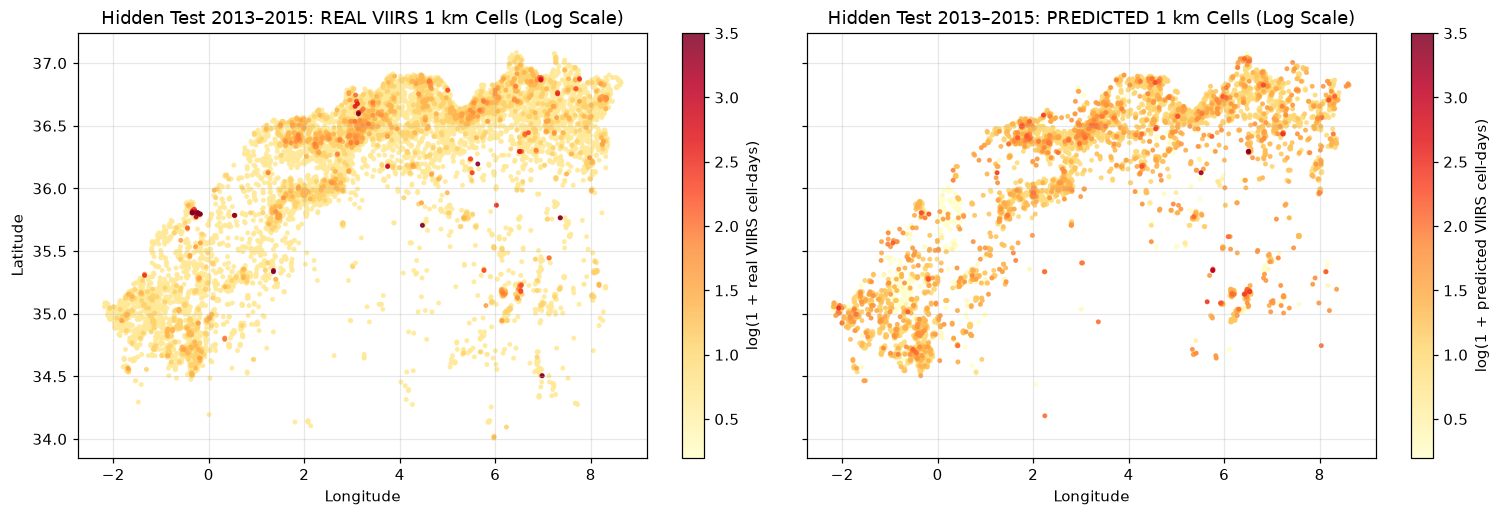

Saved 50 km harmonized dataset: C:\Everything\space-apps-fire\figures\harmonized_output\algeria_harmonized_50km_block_monthly_2002_2025.csv


In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Cap stationary industrial outliers mislabelled as type 0 (max 15 fire days/month in a single 1 km cell)
cell_1km_df["m_1km_capped"] = cell_1km_df["m_1km_celldays"].clip(upper=15.0)
cell_1km_df["raw_weight"] = cell_1km_df["m_1km_capped"] + LAMBDA_PRIOR * cell_1km_df["P_c"]
weight_sum = cell_1km_df.groupby(["by", "bx", "ym"])["raw_weight"].transform("sum")
cell_1km_df["w_cm"] = cell_1km_df["raw_weight"] / weight_sum
cell_1km_df["pred_viirs_1km"] = cell_1km_df["pred_tweedie_quad"] * cell_1km_df["w_cm"]

# 2. Validate 1 km Downscaling on Hidden Test (2013-2015): Predicted 1 km vs. Real VIIRS 1 km
test_pred_1km = (
    cell_1km_df[(cell_1km_df["year"] >= 2013) & (cell_1km_df["year"] <= 2015) & (cell_1km_df["lat_1km"] >= 34.0)]
    .groupby(["cy", "cx", "lat_1km", "lon_1km"])["pred_viirs_1km"]
    .sum()
    .reset_index()
)

test_real_1km = (
    v_1km[(v_1km["ym"] >= "2013-01") & (v_1km["ym"] <= "2015-12")]
    .assign(lat_1km=lambda d: (d["cy"] + 0.5) * 0.01, lon_1km=lambda d: (d["cx"] + 0.5) * 0.01)
)
test_real_1km = (
    test_real_1km[test_real_1km["lat_1km"] >= 34.0]
    .groupby(["cy", "cx", "lat_1km", "lon_1km"])["v_1km_celldays"]
    .sum()
    .reset_index()
)

# Plot Hidden Test (2013-2015) 1 km Spatial Comparison
p_plot = test_pred_1km[test_pred_1km["pred_viirs_1km"] >= 0.2].sort_values("pred_viirs_1km")
r_plot = test_real_1km[test_real_1km["v_1km_celldays"] >= 1].sort_values("v_1km_celldays")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharex=True, sharey=True)
vmin, vmax = 0.2, 3.5

sc0 = axes[0].scatter(r_plot["lon_1km"], r_plot["lat_1km"], c=np.log1p(r_plot["v_1km_celldays"]),
                      cmap="YlOrRd", vmin=vmin, vmax=vmax, s=5, alpha=0.85)
axes[0].set_title("Hidden Test 2013–2015: REAL VIIRS 1 km Cells (Log Scale)")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(sc0, ax=axes[0], label="log(1 + real VIIRS cell-days)")

sc1 = axes[1].scatter(p_plot["lon_1km"], p_plot["lat_1km"], c=np.log1p(p_plot["pred_viirs_1km"]),
                      cmap="YlOrRd", vmin=vmin, vmax=vmax, s=5, alpha=0.85)
axes[1].set_title("Hidden Test 2013–2015: PREDICTED 1 km Cells (Log Scale)")
axes[1].set_xlabel("Longitude")
plt.colorbar(sc1, ax=axes[1], label="log(1 + predicted VIIRS cell-days)")

plt.tight_layout()
plt.show()

# 3. Export Unified Harmonized Dataset (2002-2012 Predicted VIIRS + 2013-2025 Real VIIRS)
out_dir = FIGDIR / "harmonized_output"
out_dir.mkdir(exist_ok=True)

# (a) 50 km Block-Month Harmonized Series (2002-2025)
harmonized_50km = full_df[["by", "bx", "ym", "year", "month", "modis_celldays", "viirs_celldays", "pred_tweedie_quad"]].copy()
harmonized_50km["harmonized_viirs_celldays"] = np.where(
    harmonized_50km["year"] <= 2012,
    harmonized_50km["pred_tweedie_quad"],
    harmonized_50km["viirs_celldays"]
)
harmonized_50km.to_csv(out_dir / "algeria_harmonized_50km_block_monthly_2002_2025.csv", index=False)
print("Saved 50 km harmonized dataset:", (out_dir / "algeria_harmonized_50km_block_monthly_2002_2025.csv").resolve())